In [1]:
import xarray as xr
import pandas as pd
import numpy as np
import glob
import os
import sys
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

palette_goes_cats = {0: 'purple', 1: 'steelblue', 2: 'green', 3: 'orange', 4: 'red', 5: 'hotpink', np.nan: 'grey'}

# load the combined dataset

In [2]:
filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/CO_transitions_EC_GOES.nc'
with xr.open_dataset(filename) as ds:
    bt_co_concat = ds.load()

## plots: occurrence of transitions

In [3]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')

/tmp/ipykernel_2489839/908269067.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)


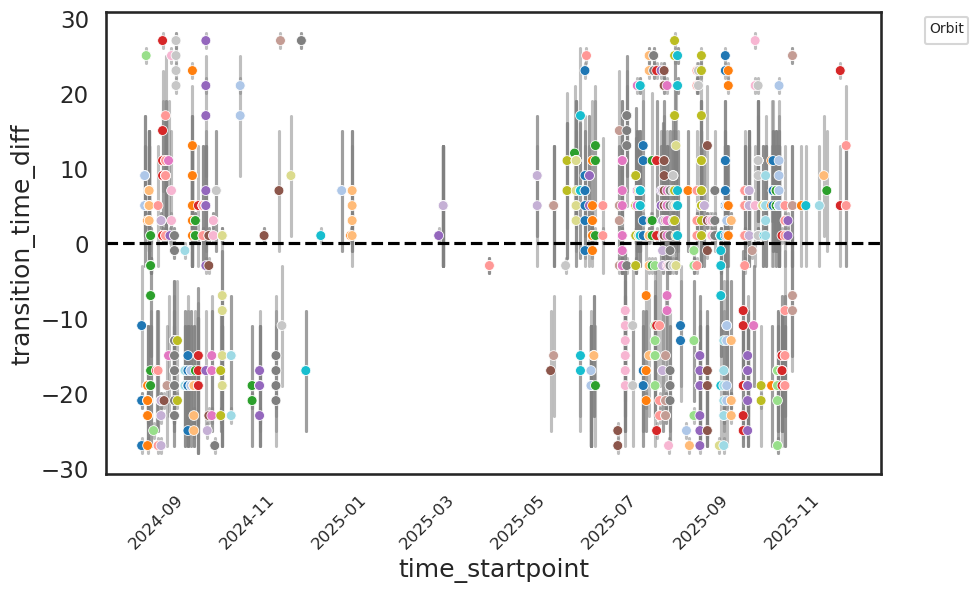

In [13]:
plt.figure(figsize=(10,6))
sns.scatterplot(data = bt_co_concat, x='time_startpoint', y='transition_time_diff', hue='orbit', palette='tab20', legend=False, s=50)
plt.xticks(rotation=45, fontsize=12, ha='right')
# add whiskers for uncertainty
for i in range(len(bt_co_concat.time_startpoint)):
    if not pd.isna(bt_co_concat.transition_time_diff.values[i]):
        plt.plot([bt_co_concat.time_startpoint.values[i], bt_co_concat.time_startpoint.values[i]], 
                 [bt_co_concat.transition_time_diff.values[i] - bt_co_concat.transition_uncertainty.values[i],
                  bt_co_concat.transition_time_diff.values[i] + bt_co_concat.transition_uncertainty.values[i]], 
                 color='gray', alpha=0.5, zorder=0)
plt.axhline(0, color='black', linestyle='--')
plt.legend(title='Orbit', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=7, title_fontsize=10)

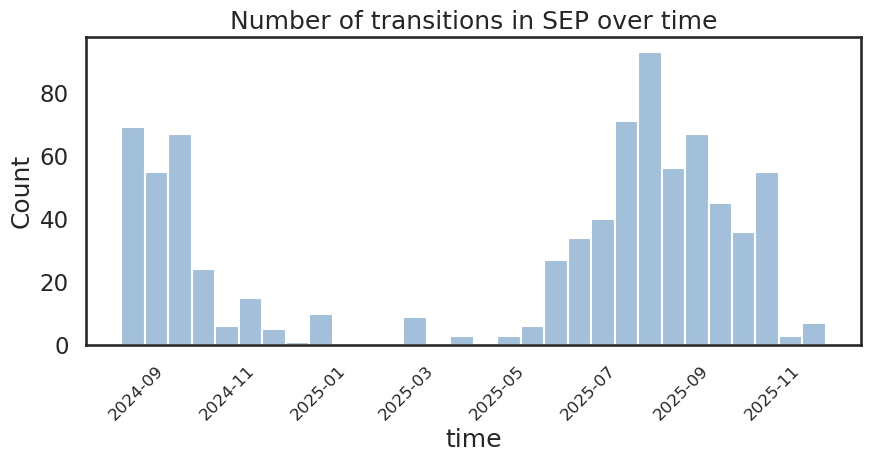

In [4]:
plt.figure(figsize=(10,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='time_startpoint', bins=30, color='steelblue', alpha=0.5)
plt.xticks(rotation=45, fontsize=12, ha='right')
plt.title('Number of transitions in SEP over time')
plt.xlabel('time')
plt.savefig('./figures/transition_count_over_time.png', bbox_inches='tight')

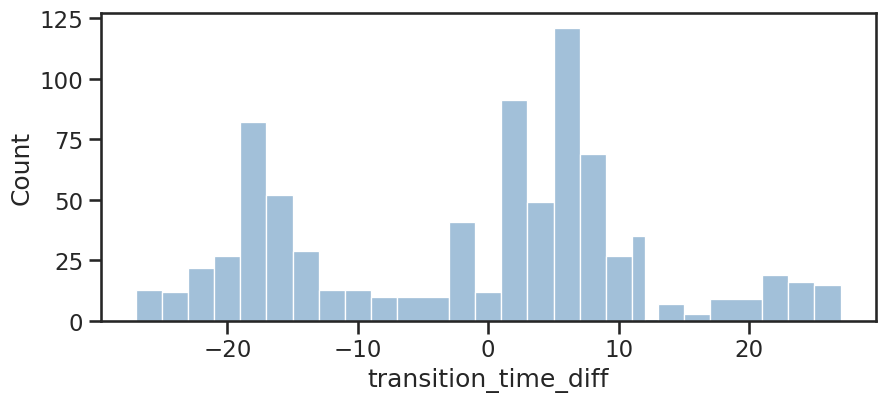

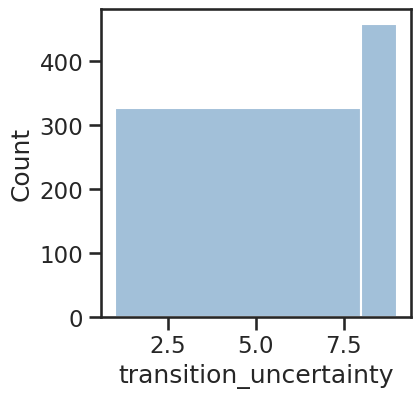

fraction of daytime transitions:  0.40396530359355637
transition_time_diff for daytime transitions:  [-27. -25. -23. -21.  -3.  -1.   1.   3.  21.  23.  25.  27.]
transition_time_diff for nighttime transitions:  [-19. -17. -15. -13. -11.  -9.  -7.   5.   7.   9.  11.  12.  13.  15.
  17.]


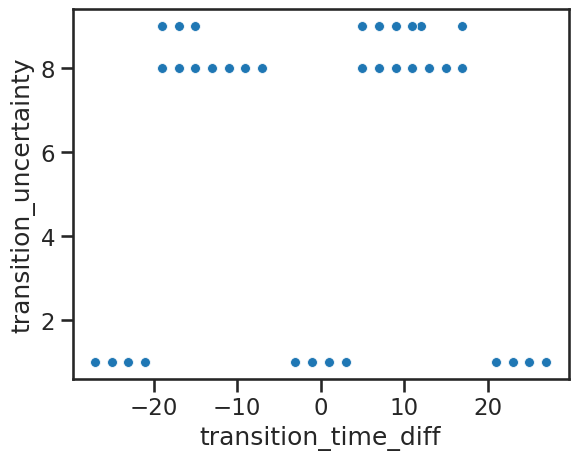

In [59]:
plt.figure(figsize=(10,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_time_diff', 
             bins=np.unique(bt_co_concat.transition_time_diff), color='steelblue', alpha=0.5)
plt.show()
plt.figure(figsize=(4,4))
sns.histplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_uncertainty', 
             bins=np.unique(bt_co_concat.transition_uncertainty), color='steelblue', alpha=0.5)
plt.show()
daytime_trans = (bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True)['transition_uncertainty'] < 3)
nighttime_trans = (bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True)['transition_uncertainty'] >= 3)
print("fraction of daytime transitions: ", (daytime_trans.sum() / (daytime_trans.sum() + nighttime_trans.sum())).values)


sns.scatterplot(data = bt_co_concat.where((bt_co_concat.transition_flag == True), drop=True), x='transition_time_diff', y='transition_uncertainty', legend=False, s=50)
print('transition_time_diff for daytime transitions: ', np.unique(bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_uncertainty < 3), drop=True)['transition_time_diff'].values))
print('transition_time_diff for nighttime transitions: ', np.unique(bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_uncertainty > 3), drop=True)['transition_time_diff'].values))
plt.show()

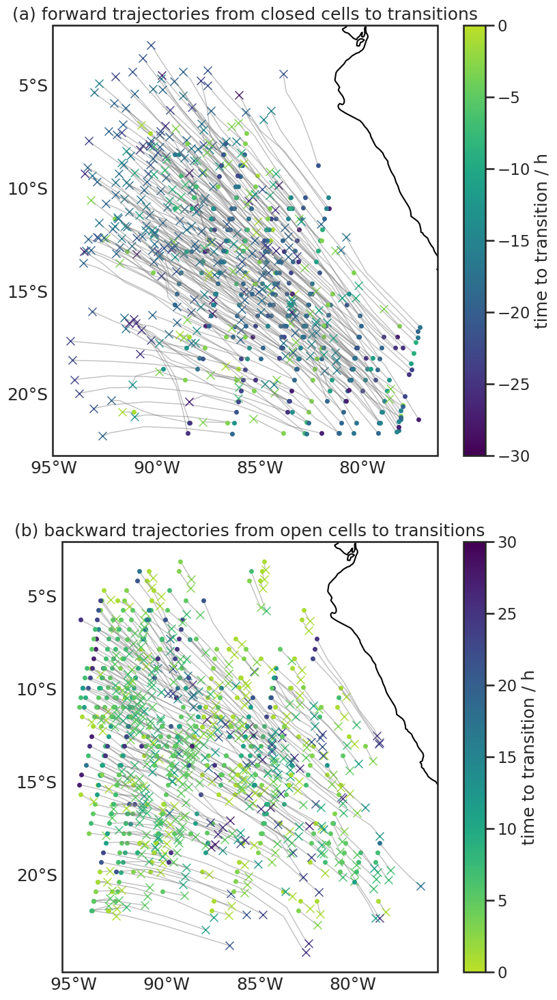

In [13]:
import matplotlib as mpl
import matplotlib.ticker as mticker
import cartopy.crs as ccrs

fig, (ax1,ax2) = plt.subplots(2,1, figsize=(10, 18), subplot_kw={'projection': ccrs.PlateCarree()})
for ax in [ax1, ax2]:
    ax.coastlines()
    gl = ax.gridlines(crs=ccrs.PlateCarree(), draw_labels=True)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlines = False
    gl.ylines = False
    gl.xlocator = mticker.FixedLocator([-95, -90, -85, -80, -75])
    gl.ylocator = mticker.FixedLocator([-25, -20, -15, -10, -5])

ax=ax1
bt_co_forward_from_c_with_trans = bt_co_concat.where((bt_co_concat.transition_flag==True) & (bt_co_concat.cats == 1), drop=True)
for startpoint in bt_co_forward_from_c_with_trans.time_startpoint.values:
    tmp = bt_co_forward_from_c_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(0,50)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(0,transition_timestep+1))
    
    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=-30, vmax=0)
    cmap = plt.get_cmap("viridis")
    cmap = mpl.colors.LinearSegmentedColormap.from_list("viridis_cropped", cmap(np.linspace(0, 0.9, 256)))
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax,x=tmp.lon_traj, y=tmp.lat_traj, color='grey', alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    # sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    # plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
    #sns.scatterplot(data=tmp, x='lon_traj', y='lat_traj', hue='goes_cats', palette=palette_goes_cats, legend=False, s=50, marker='o')
#plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition / h")
ax.set_title('(a) forward trajectories from closed cells to transitions')

ax=ax2
bt_co_back_from_o_with_trans = bt_co_concat.where((bt_co_concat.transition_flag==True) & (bt_co_concat.cats == 2), drop=True)
for startpoint in bt_co_back_from_o_with_trans.time_startpoint.values:
    tmp = bt_co_back_from_o_with_trans.sel(time_startpoint=startpoint).sel(timestep=slice(-50,1)).sortby('timestep')
    #orbit = tmp.orbit_startpoint.values
    transition_timestep = tmp.transition_timestep.values
    tmp = tmp.sel(timestep=slice(transition_timestep,0))

    x_0 = tmp.sel(timestep=0).lon_traj.values.item()
    y_0 = tmp.sel(timestep=0).lat_traj.values.item()
    x_t = tmp.sel(timestep=transition_timestep).lon_traj.values.item()
    y_t = tmp.sel(timestep=transition_timestep).lat_traj.values.item()

    val = float(tmp.transition_time_diff.values) 
    norm = mpl.colors.Normalize(vmin=0, vmax=30)
    cmap = plt.get_cmap("viridis_r")
    cmap = mpl.colors.LinearSegmentedColormap.from_list("viridis_cropped", cmap(np.linspace(0.1, 1, 256)))
    rgba = cmap(norm(val))

    sns.lineplot(ax=ax, x=tmp.lon_traj, y=tmp.lat_traj, color='grey', alpha=0.5, lw=1)
    ax.plot(x_0, y_0, marker='o',  ms=4, lw=0, color=rgba)
    ax.plot(x_t, y_t, marker='x', ms=8, lw=0, color=rgba)
    
    #sns.lineplot(x=tmp.lon_traj, y=tmp.lat_traj, color='gray', alpha=0.5)
    #plt.plot([tmp.sel(timestep=0).lon_traj.values], [tmp.sel(timestep=0).lat_traj.values], 'ko', ms=4)
    #plt.plot([tmp.sel(timestep=transition_timestep).lon_traj.values], [tmp.sel(timestep=transition_timestep).lat_traj.values], 'X', ms=7, color='black')
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
plt.colorbar(sm, ax=ax, label="time to transition / h")
ax.set_title('(b) backward trajectories from open cells to transitions')
plt.savefig('./figures/trajectories_of_transitions.png', bbox_inches='tight')

# CO transitions

#### get ACMCAP climatological median

In [4]:
acmcap_dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu.h5'
acmcap = pd.read_hdf(acmcap_dataset_filename, key='StCu')

# only need SEP data
acmcap = acmcap[acmcap.stratus_region_index == 2]

ds_acmcap = acmcap.to_xarray()
ds_acmcap = ds_acmcap.rename({'time_mid':'time_startpoint'})
ds_acmcap = ds_acmcap.swap_dims({'index':'time_startpoint'})
ds_acmcap = ds_acmcap.assign_coords({
    'time_startpoint': ds_acmcap.time_startpoint.values,
    'orbit': ('time_startpoint', ds_acmcap.orbit.values)})
ds_acmcap = ds_acmcap.drop_vars(['index'])

ds_acmcap['time_startpoint'] = ds_acmcap.time_startpoint.dt.round('0.1s')
ds_acmcap = ds_acmcap.assign_coords({'timestep': ('timestep', [0])})

ds_acmcap

<xarray.Dataset> Size: 11MB
Dimensions:                               (time_startpoint: 12979, timestep: 1)
Coordinates:
    orbit                                 (time_startpoint) object 104kB '010...
  * time_startpoint                       (time_startpoint) datetime64[ns] 104kB ...
  * timestep                              (timestep) int64 8B 0
Data variables: (12/106)
    scene_id                              (time_startpoint) int64 104kB 25868...
    stratus_region_index                  (time_startpoint) int64 104kB 2 ... 2
    along_track_mid                       (time_startpoint) float64 104kB 128...
    lon_mid                               (time_startpoint) float64 104kB -85...
    lat_mid                               (time_startpoint) float64 104kB -3....
    lat_min                               (time_startpoint) float64 104kB -3....
    ...                                    ...
    rwc_cbh_perc75                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc95                        (time_startpoint) float64 104kB nan...
    rwc_cbh_perc05                        (time_startpoint) float64 104kB nan...
    rain_gini                             (time_startpoint) float64 104kB 0.0...
    rain_lcf                              (time_startpoint) float64 104kB 0.0...
    rain_n_clusters                       (time_startpoint) int64 104kB 0 ... 3

In [5]:
ds_acmcap['rain_fraction_no_zero'] = ds_acmcap['rain_fraction'].where(ds_acmcap['rain_fraction'] != 0, np.nan)
for var in ['cbh_m', 'cth_m', 'lwp', 'ER', 'Nd', 'rwp', 'rain_median_volume_diameter']:
    ds_acmcap[var+'_cv'] = ds_acmcap[var+'_std'] / ds_acmcap[var]
acmcap_climatology_median = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').median()
acmcap_climatology_std = ds_acmcap.where(ds_acmcap.cats.isin([1,2]), drop=True).groupby('cats').std()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension cats because variable cats is not a coordinate. To create an index for cats, please first call `.set_coords('cats')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


In [6]:
acmcap_climatology_median

<xarray.Dataset> Size: 2kB
Dimensions:                               (cats: 2, timestep: 1)
Coordinates:
  * timestep                              (timestep) int64 8B 0
  * cats                                  (cats) float64 16B 1.0 2.0
Data variables: (12/113)
    scene_id                              (cats) float64 16B 3.435e+04 3.495e+04
    stratus_region_index                  (cats) float64 16B 2.0 2.0
    along_track_mid                       (cats) float64 16B 2.56e+03 2.304e+03
    lon_mid                               (cats) float64 16B -84.02 -88.24
    lat_mid                               (cats) float64 16B -14.02 -11.94
    lat_min                               (cats) float64 16B -14.49 -12.42
    ...                                    ...
    cth_m_cv                              (cats) float64 16B 0.0532 0.1241
    lwp_cv                                (cats) float64 16B 0.6288 1.37
    ER_cv                                 (cats) float64 16B 0.2746 0.6398
    Nd_cv                                 (cats) float64 16B 0.4417 0.6385
    rwp_cv                                (cats) float64 16B 1.323 1.777
    rain_median_volume_diameter_cv        (cats) float64 16B 0.2866 0.3919

## ACMCAP variables as function of time-to-transition

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


(-30.0, 30.0)

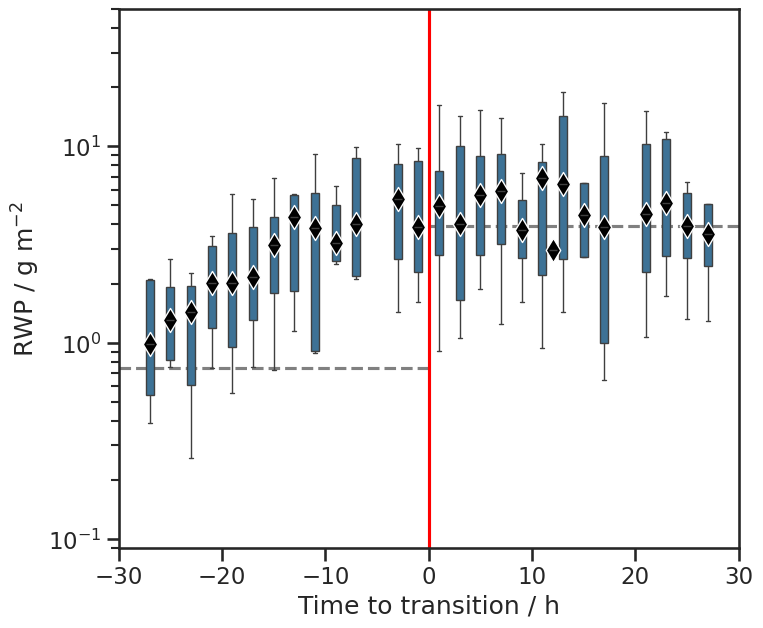

In [9]:
sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

plt.figure(figsize=(8, 7))
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=1)*1e3, xmin=-30, xmax=0, color='grey', linestyle='--')
plt.hlines(acmcap_climatology_median['rwp'].sel(cats=2)*1e3, xmin=0, xmax=30, color='grey', linestyle='--')
#plt.hlines(y=bt_non_trans_c['rwp'].median()*1e3, xmin=-30, xmax=0, color='orange', linestyle='-')
#plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.25)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)
#plt.hlines(y=bt_non_trans_c['rwp'].quantile(0.75)*1e3, xmin=-30, xmax=0, color='orange', linestyle='-', alpha=0.5)

sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, whis=(10, 90), native_scale=True, showfliers=False, saturation=0.6)
tmp = bt_co_concat[['transition_time_diff', 'rwp']].groupby('transition_time_diff').median()
sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp['rwp']*1e3, color='black', marker='d', s=150, zorder=2)

plt.yscale('log')
plt.ylim(9e-2, 5e1)
#plt.ylim(0, 15)
plt.xlabel('Time to transition / h')
plt.ylabel('RWP / g m$^{-2}$')
plt.axvline(0, color='red', linestyle='-')
plt.xlim(-30, 30)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

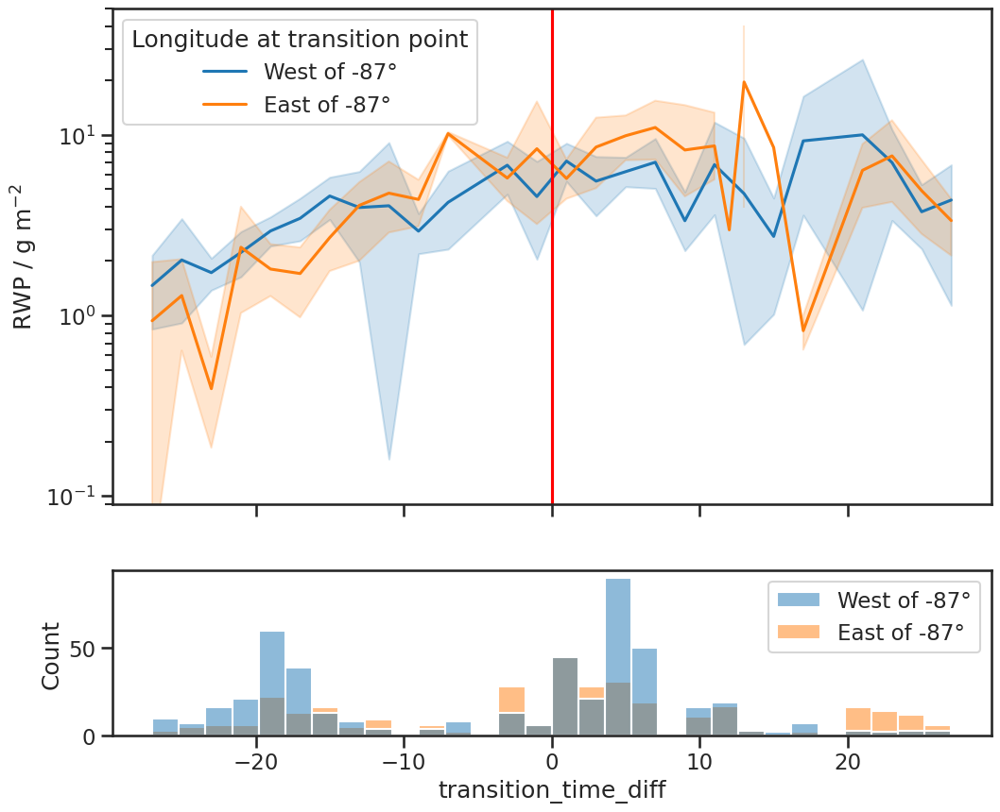

In [79]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
tmp = bt_co_concat.where(bt_co_concat.transition_flag==1, drop=True)
lon_at_transition = (tmp.sel(timestep=tmp.transition_timestep).lon_traj < -87)
lon_at_transition = np.where(lon_at_transition.values==True, 'West of -87°', 'East of -87°')
sns.lineplot(ax=ax0, data = tmp, x='transition_time_diff', y=tmp['rwp']*1e3, hue=lon_at_transition)
ax0.set_yscale('log')
ax0.set_ylim(9e-2, 5e1)
ax0.legend(title='Longitude at transition point')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = tmp, x='transition_time_diff', hue=lon_at_transition, bins=30, color='steelblue', alpha=0.5)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

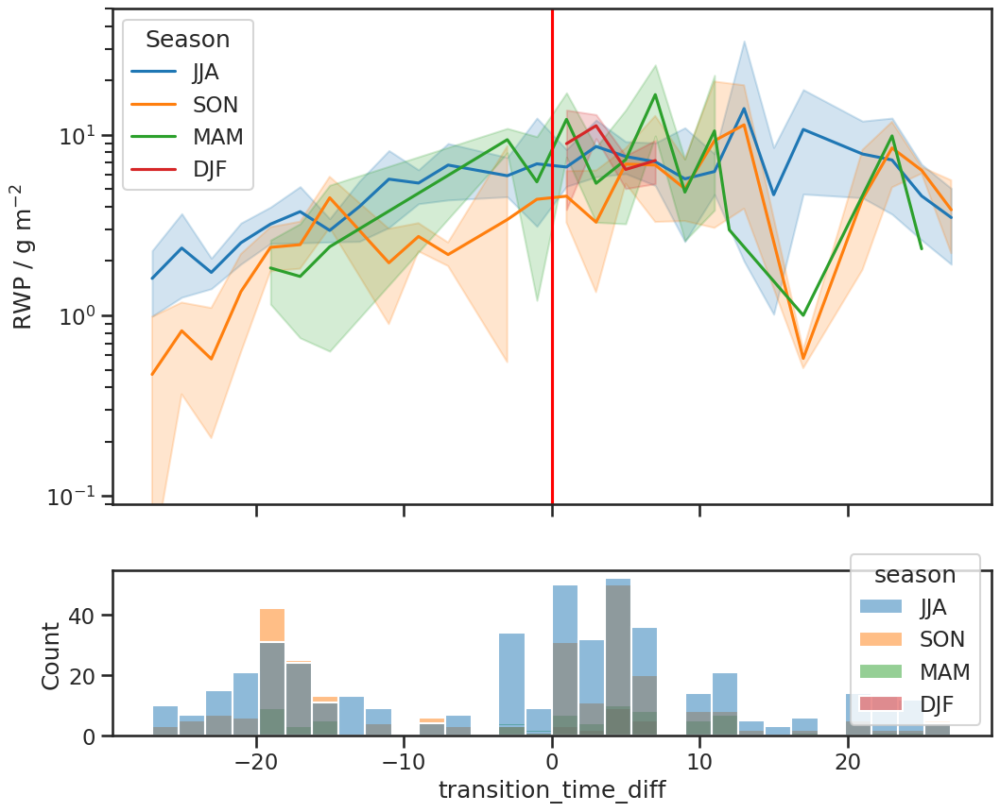

In [80]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
tmp = bt_co_concat.where(bt_co_concat.transition_flag==1, drop=True)
tmp['season'] = tmp.time_startpoint.dt.season
sns.lineplot(ax=ax0, data = tmp, x='transition_time_diff', y=tmp['rwp']*1e3, hue='season')
ax0.set_yscale('log')
ax0.set_ylim(9e-2, 5e1)
ax0.legend(title='Season')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = tmp, x='transition_time_diff', hue='season', bins=30, color='steelblue', alpha=0.5)

<Axes: xlabel='transition_time_diff', ylabel='Count'>

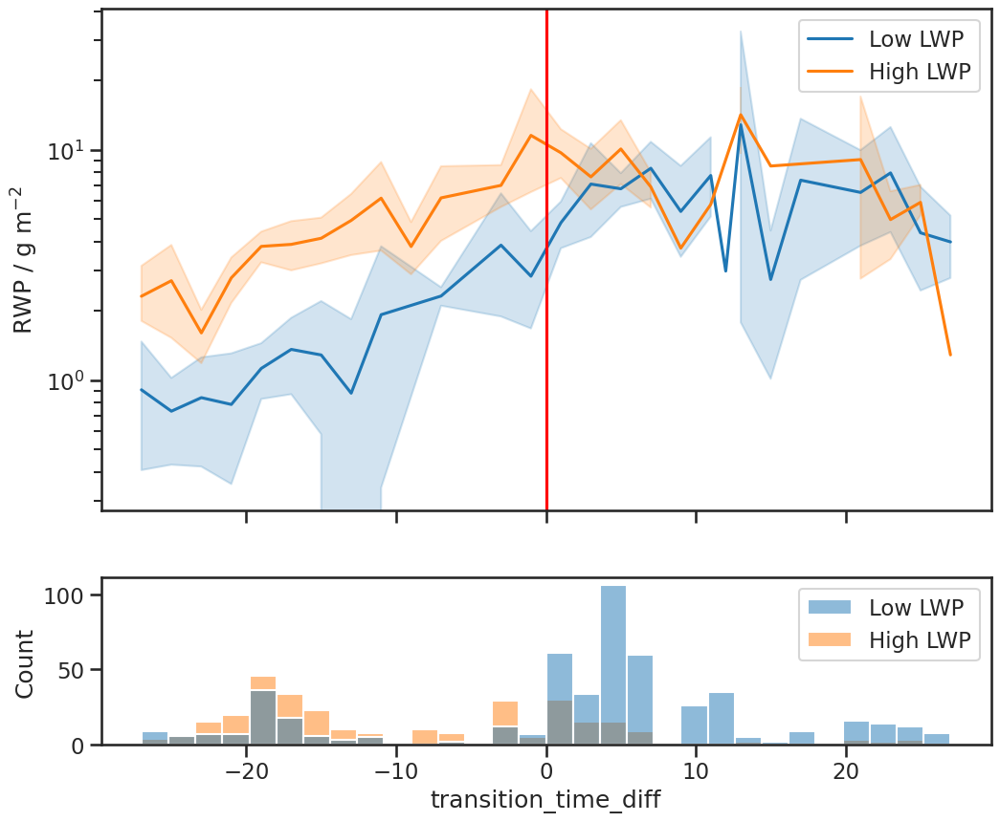

In [81]:
fig, (ax0, ax1) = plt.subplots(2,1, figsize=(12, 10), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
lwp_bins = (bt_co_concat.lwp > 5e-2)
lwp_bins = np.where(lwp_bins.values==True, 'High LWP', 'Low LWP')
sns.lineplot(ax=ax0, data = bt_co_concat, x='transition_time_diff', y=bt_co_concat['rwp']*1e3, hue=lwp_bins)
ax0.set_yscale('log')
#ax0.legend(title='LWP category')
ax0.set_xlabel('Time to transition / h')
ax0.set_ylabel('RWP / g m$^{-2}$')
ax0.axvline(0, color='red', linestyle='-')

sns.histplot(ax=ax1, data = bt_co_concat, x='transition_time_diff', hue=lwp_bins, bins=30, color='steelblue', alpha=0.5)

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2544272/3106481172.py:4: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
/tmp/ipykernel_2544272/3106481172.py:6: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (6e1, 1.8e2), 'y_scale': 'linear'},
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


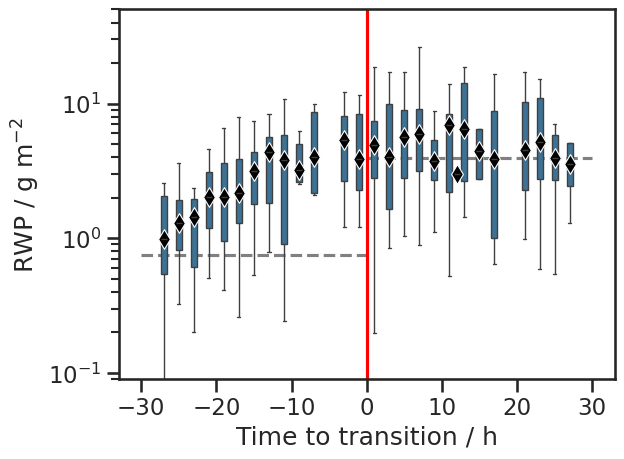

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


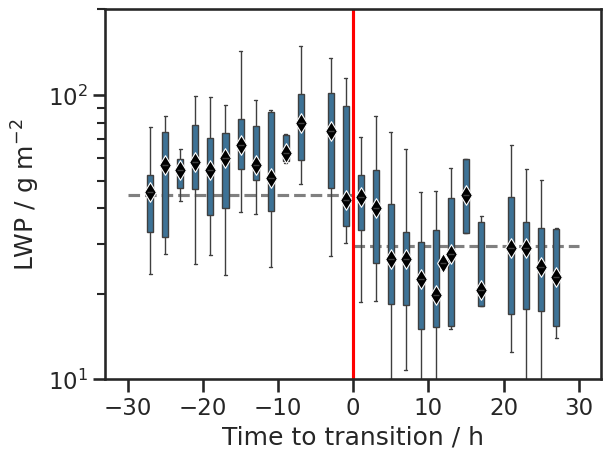

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


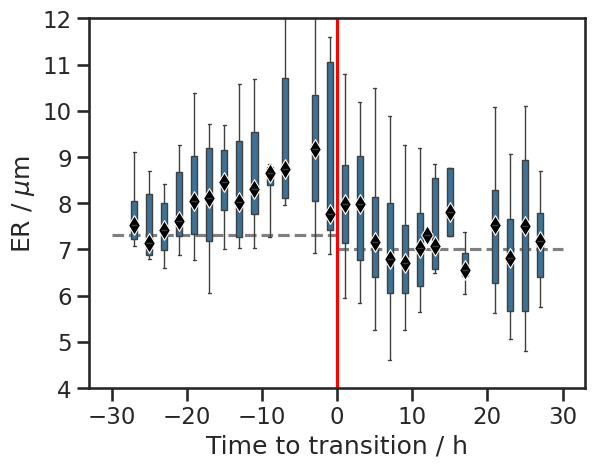

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


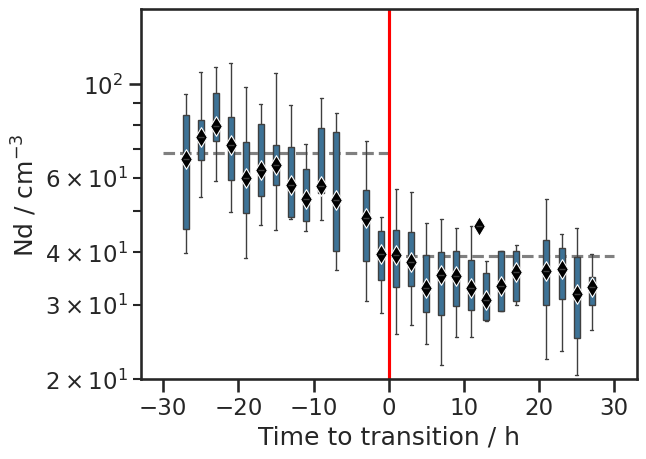

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


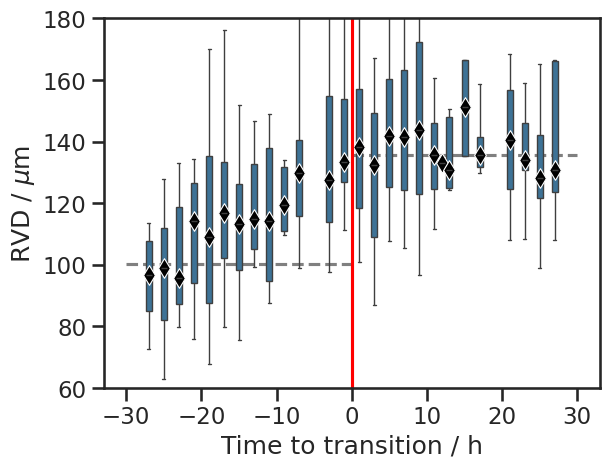

In [ ]:
plot_params = {
    'rwp': {'factor': 1e3, 'y_label': 'RWP / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'lwp': {'factor': 1e3, 'y_label': 'LWP / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': '$r_e$ / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': '$N_d$ / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': '$D_0$ / $\mu$m', 'y_lim': (6e1, 1.8e2), 'y_scale': 'linear'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()


/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

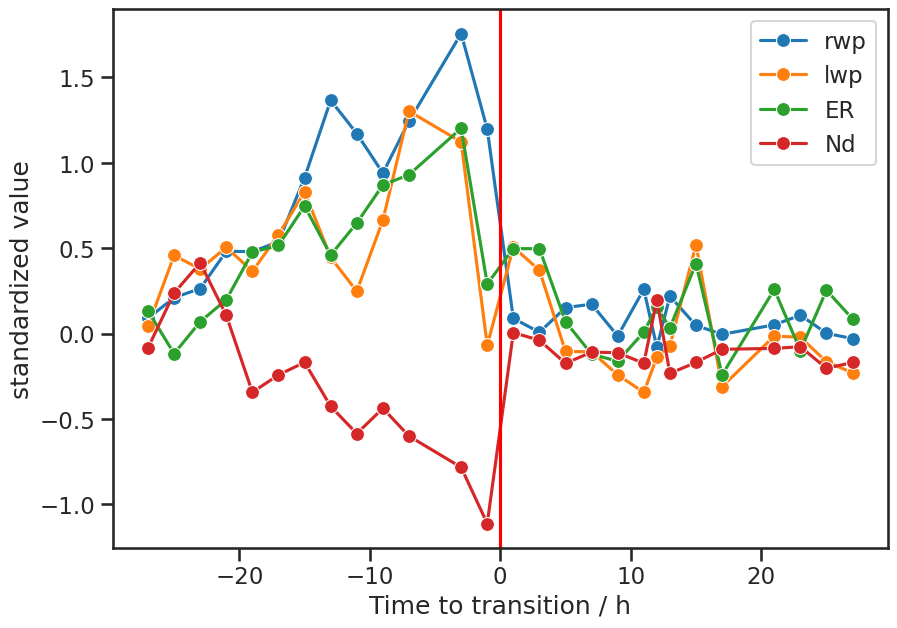

In [117]:
vars = ['rwp', 'lwp', 'ER', 'Nd']


plt.figure(figsize=(10, 7))
for var in vars:
    tmp_1 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 1), drop=True)[['transition_time_diff', var]]
    tmp_2 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 2), drop=True)[['transition_time_diff', var]]
    rwp_1_standardized = (tmp_1[var] - acmcap_climatology_median[var].sel(cats=1)) / acmcap_climatology_std[var].sel(cats=1)
    rwp_2_standardized = (tmp_2[var] - acmcap_climatology_median[var].sel(cats=2)) / acmcap_climatology_std[var].sel(cats=2)
    tmp_1[var + '_standardized'] = rwp_1_standardized.drop_vars('cats') 
    tmp_2[var + '_standardized'] = rwp_2_standardized.drop_vars('cats')
    tmp = xr.concat([tmp_1, tmp_2], dim='time_startpoint')

    #sns.boxplot(x= tmp['transition_time_diff'], y=tmp[var + '_standardized'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp_median = tmp.groupby('transition_time_diff').median()
    sns.lineplot(data=tmp_median, x='transition_time_diff', y=tmp_median[var + '_standardized'], marker='o', markersize=10, label=var)

plt.xlabel('Time to transition / h')
plt.ylabel('standardized value')
plt.axvline(0, color='red', linestyle='-')
plt.legend()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

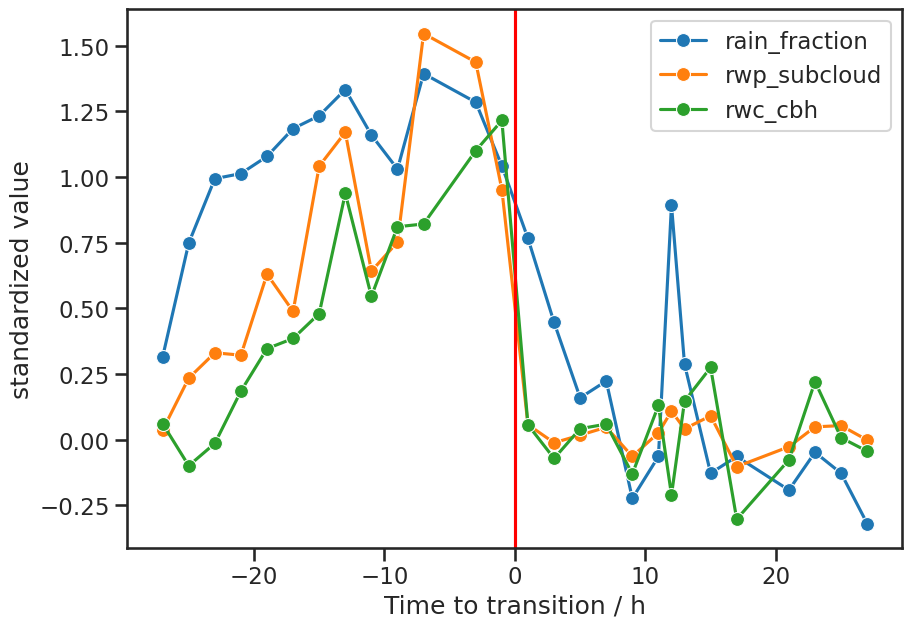

In [84]:
vars = ['rain_fraction', 'rwp_subcloud', 'rwc_cbh'] # 'rain_median_volume_diameter',

plt.figure(figsize=(10, 7))
for var in vars:
    tmp_1 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 1), drop=True)[['transition_time_diff', var]]
    tmp_2 = bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.cats == 2), drop=True)[['transition_time_diff', var]]
    rwp_1_standardized = (tmp_1[var] - acmcap_climatology_median[var].sel(cats=1)) / acmcap_climatology_std[var].sel(cats=1)
    rwp_2_standardized = (tmp_2[var] - acmcap_climatology_median[var].sel(cats=2)) / acmcap_climatology_std[var].sel(cats=2)
    tmp_1[var + '_standardized'] = rwp_1_standardized.drop_vars('cats') 
    tmp_2[var + '_standardized'] = rwp_2_standardized.drop_vars('cats')
    tmp = xr.concat([tmp_1, tmp_2], dim='time_startpoint')

    #sns.boxplot(x= tmp['transition_time_diff'], y=tmp[var + '_standardized'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp_median = tmp.groupby('transition_time_diff').median()
    sns.lineplot(data=tmp_median, x='transition_time_diff', y=tmp_median[var + '_standardized'], marker='o', markersize=10, label=var)

plt.xlabel('Time to transition / h')
plt.ylabel('standardized value')
plt.axvline(0, color='red', linestyle='-')
plt.legend()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


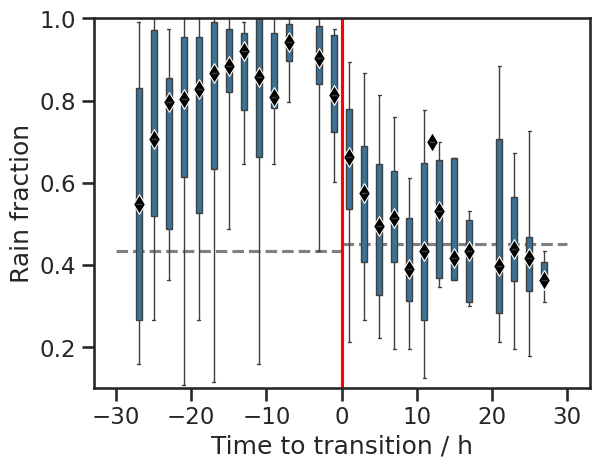

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


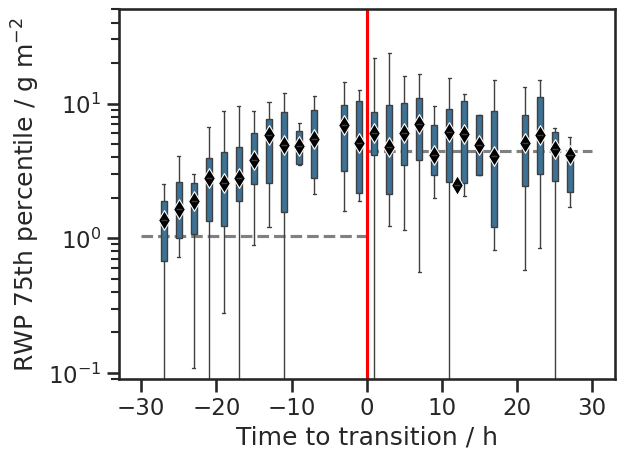

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


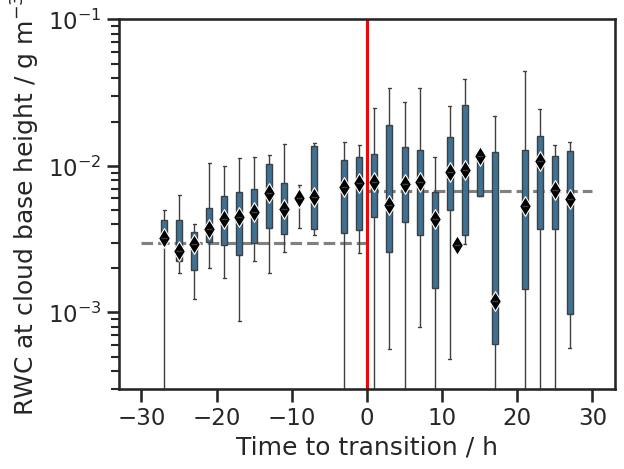

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


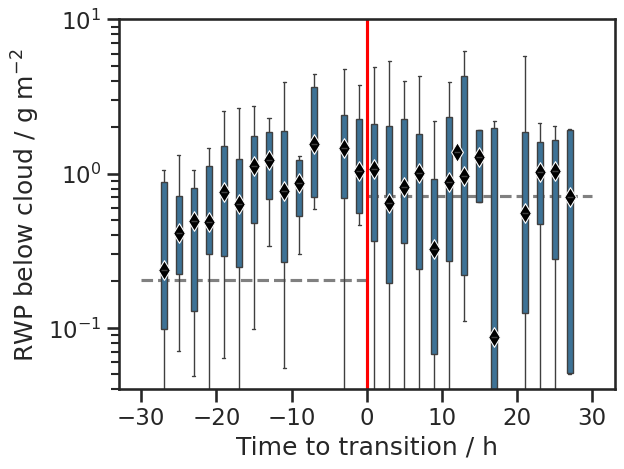

In [85]:
plot_params = {
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwp_perc75': {'factor': 1e3, 'y_label': 'RWP 75th percentile / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'RWC at cloud base height / g m$^{-3}$', 'y_lim': (3e-4, 1e-1), 'y_scale': 'log'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'RWP below cloud / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()

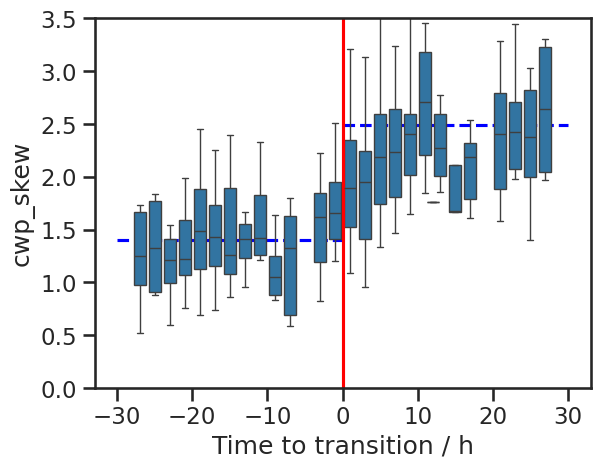

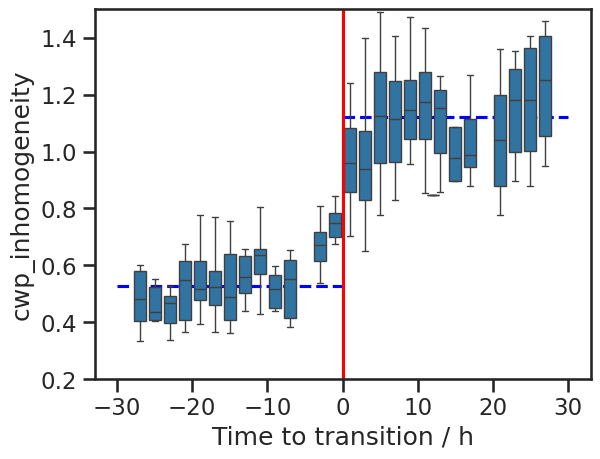

In [87]:
var = 'cwp_skew'
ylim = (0, 3.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
#plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

var = 'cwp_inhomogeneity'
ylim = (0.2, 1.5)
yscale = 'linear'
plt.hlines(acmcap_climatology_median[var].sel(cats=1), xmin=-30, xmax=0, color='blue', linestyle='--')
plt.hlines(acmcap_climatology_median[var].sel(cats=2), xmin=0, xmax=30, color='blue', linestyle='--')
#plt.hlines(y=bt_non_trans_c[var].median(), xmin=-30, xmax=0, color='blue', linestyle='-')
sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=var, whis=(5, 95), native_scale=True, gap=3, showfliers=False)
plt.axvline(0, color='red', linestyle='-')
plt.yscale(yscale)
plt.ylim(ylim)
plt.xlabel('Time to transition / h')
plt.show()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


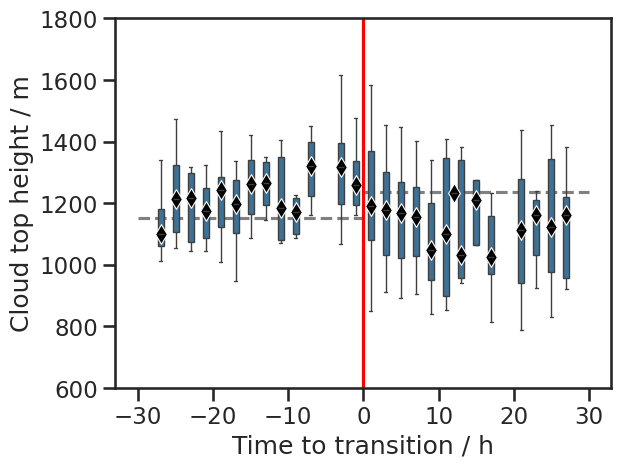

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


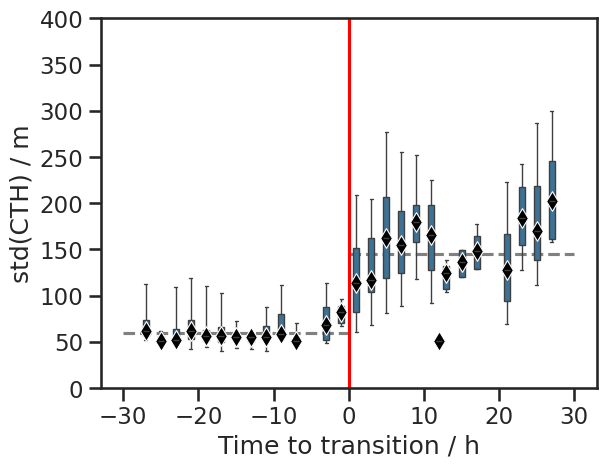

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


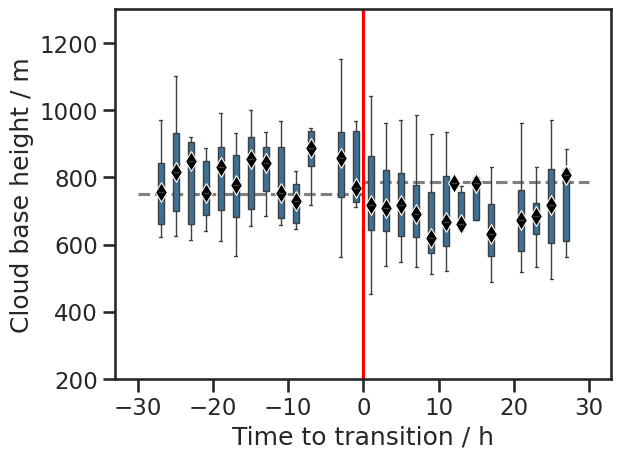

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


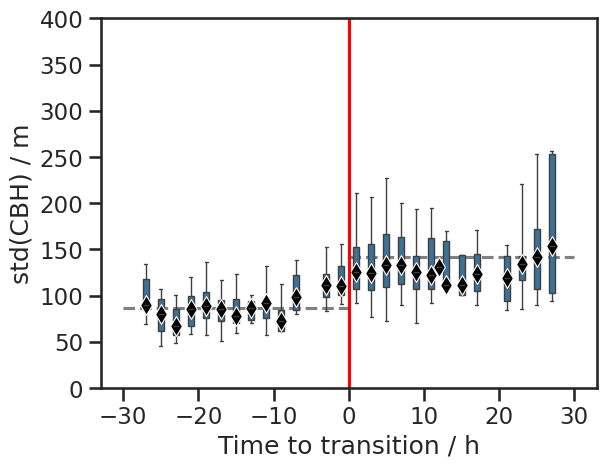

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


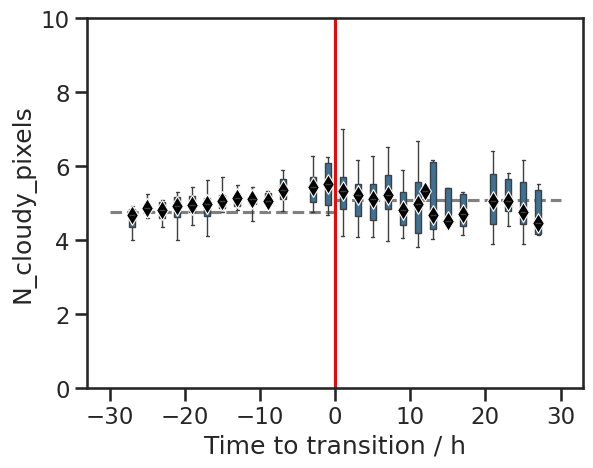

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


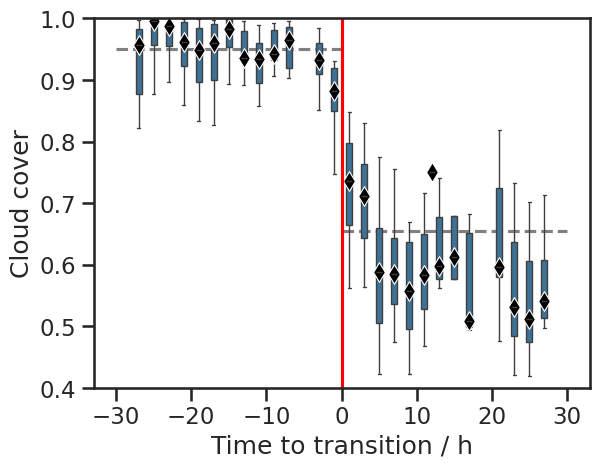

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)


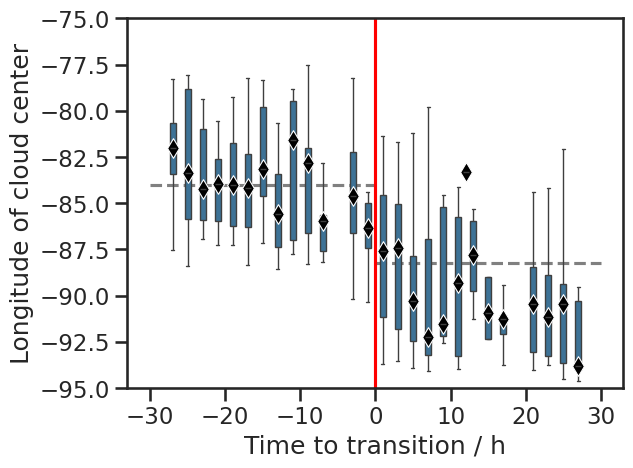

In [88]:
plot_params = {
    'cth_m': {'factor': 1, 'y_label': 'Cloud top height / m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_std': {'factor': 1e0, 'y_label': 'std(CTH) / m', 'y_lim': (0, 400), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1e0, 'y_label': 'Cloud base height / m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_std': {'factor': 1e0, 'y_label': 'std(CBH) / m', 'y_lim': (0, 400), 'y_scale': 'linear'},
    'N_cloudy_pixels': {'factor': 1, 'y_label': 'N_cloudy_pixels', 'y_lim': (0, 10), 'y_scale': 'linear'},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'lon_mid': {'factor': 1, 'y_label': 'Longitude of cloud center', 'y_lim': (-95, -75), 'y_scale': 'linear'},
}

for var, params in plot_params.items():
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')
    plt.show()

### overview plot for publication

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

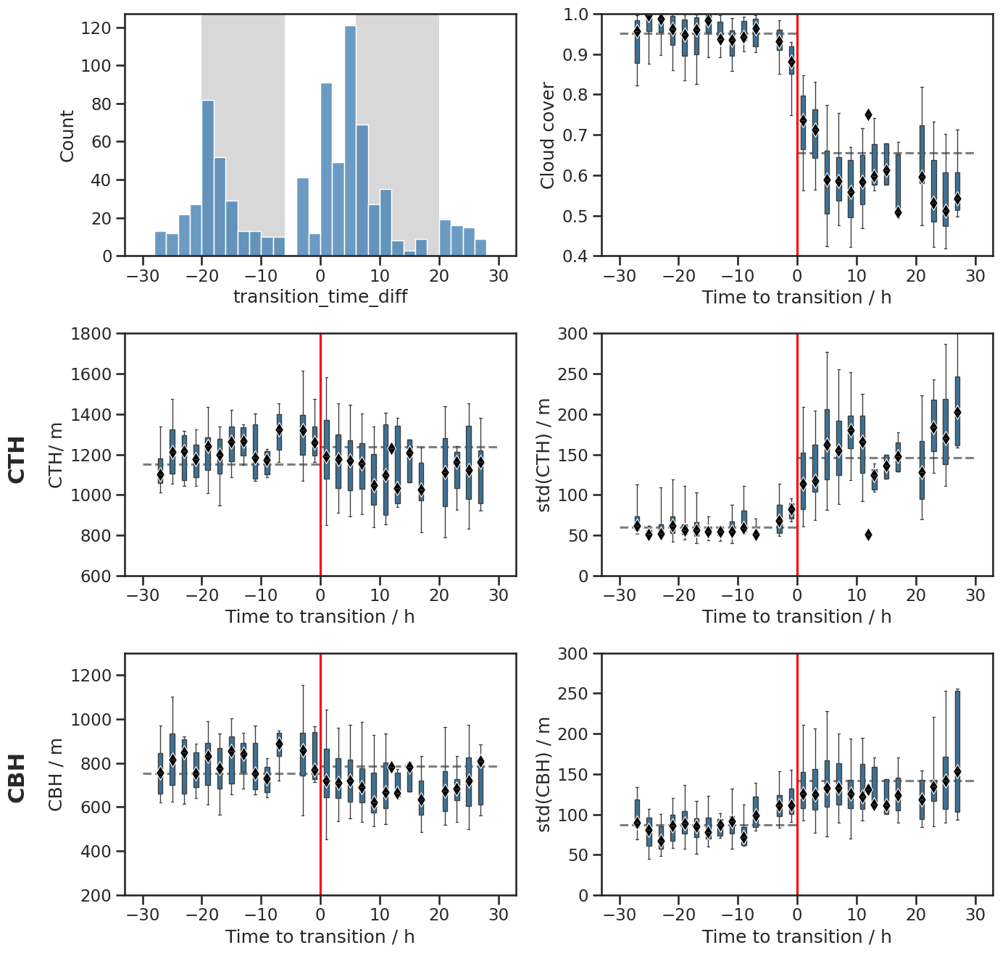

In [ ]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'CTH/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_std': {'factor': 1e0, 'y_label': 'std(CTH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1e0, 'y_label': 'CBH / m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_std': {'factor': 1e0, 'y_label': 'std(CBH) / m', 'y_lim': (0, 300), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_co_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
plt.xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

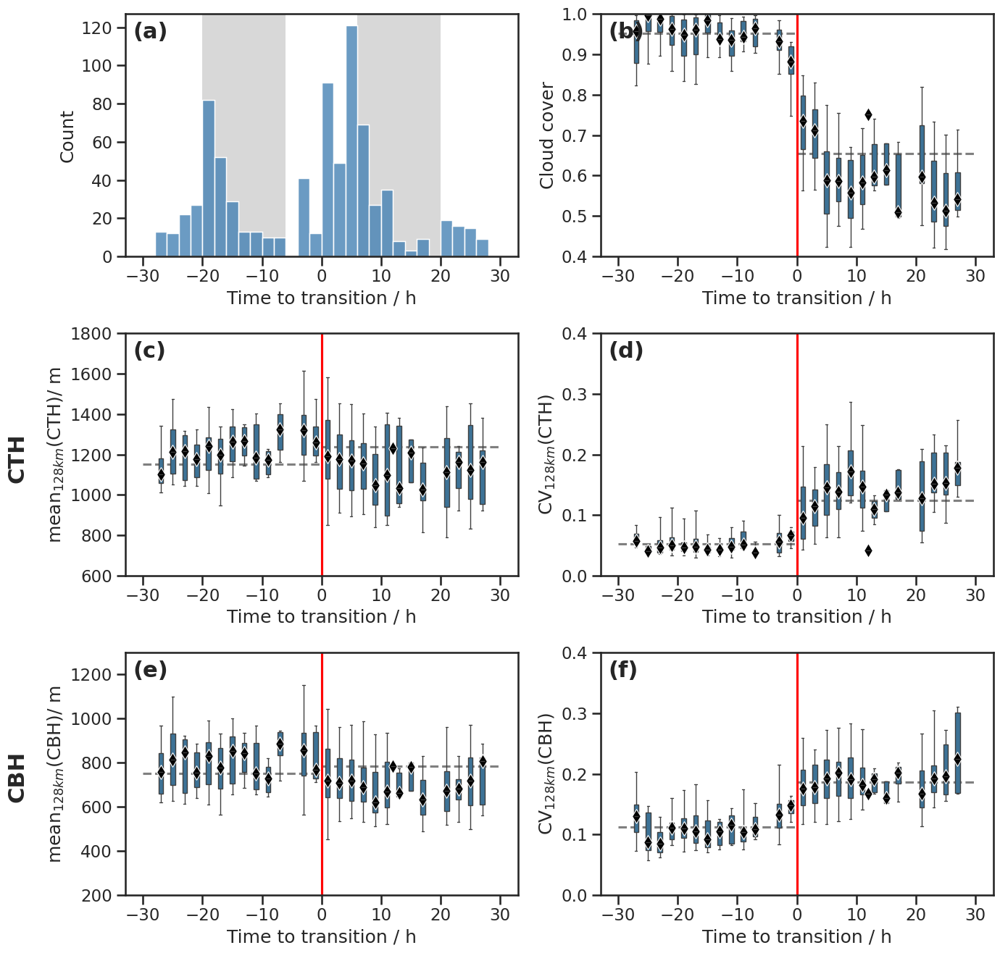

In [45]:
plot_params = {
    'no_plot': {},
    'cloud_cover': {'factor': 1, 'y_label': 'Cloud cover', 'y_lim': (0.4, 1), 'y_scale': 'linear'},
    'cth_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CTH)/ m', 'y_lim': (600, 1800), 'y_scale': 'linear'},
    'cth_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CTH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
    'cbh_m': {'factor': 1, 'y_label': 'mean$_{128km}$(CBH)/ m', 'y_lim': (200, 1300), 'y_scale': 'linear'},
    'cbh_m_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(CBH)', 'y_lim': (0, 0.4), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 3
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

# add grey background for nighttime periods
axs[0].axvspan(-20, -6, color='grey', alpha=0.3, lw=0)
axs[0].axvspan(6, 20, color='grey', alpha=0.3, lw=0)
sns.histplot(ax=axs[0], data = bt_co_concat, x='transition_time_diff', bins=np.linspace(-30, 30, 31), color='steelblue', alpha=0.8)
axs[0].set_xlabel('Time to transition / h')

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

#axs[2].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
#axs[3].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[0].annotate('(a)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('(b)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[2].annotate('(c)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[3].annotate('(d)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[4].annotate('(e)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[5].annotate('(f)', xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['','CTH','CBH']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()

plt.savefig('./figures/cbh_cth_vs_time.png', bbox_inches='tight')

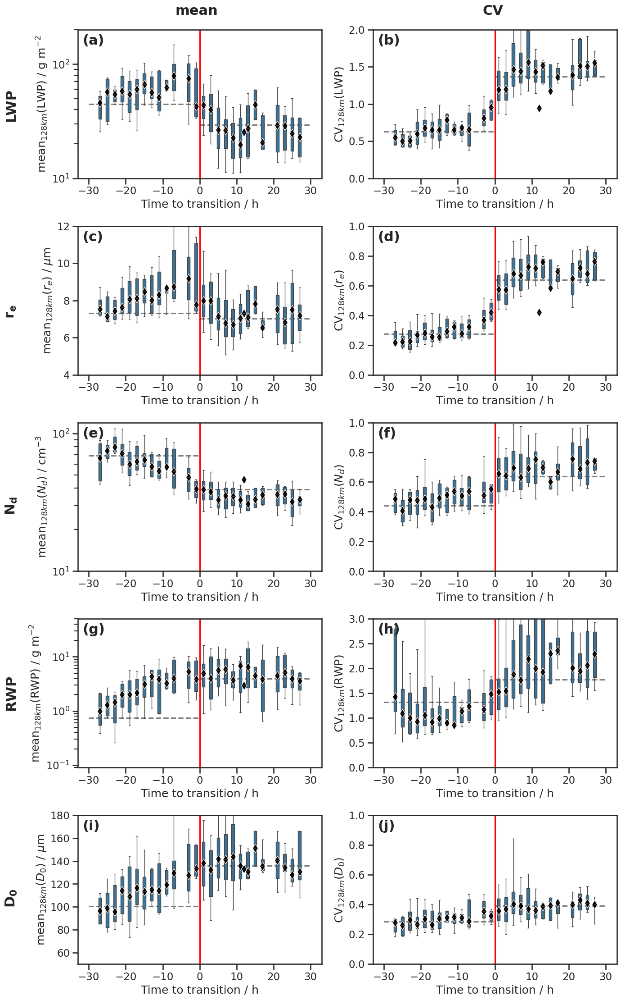

In [61]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'lwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(LWP)', 'y_lim': (0, 2), 'y_scale': 'linear'},
    'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$($r_e$) / $\mu$m', 'y_lim': (4, 12), 'y_scale': 'linear'},
    'ER_cv': {'factor':1, 'y_label': 'CV$_{128km}$($r_e$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'mean$_{128km}$($N_d$) / cm$^{-3}$', 'y_lim': (1e1, 1.2e2), 'y_scale': 'log'},
    'Nd_cv': {'factor': 1, 'y_label': 'CV$_{128km}$($N_d$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
    'rwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwp_cv': {'factor': 1, 'y_label': 'CV$_{128km}$(RWP)', 'y_lim': (0, 3), 'y_scale': 'linear'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$($D_0$) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_median_volume_diameter_cv': {'factor':1, 'y_label': 'CV$_{128km}$($D_0$)', 'y_lim': (0, 1), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(10, 90), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('CV', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['(a)','(b)','(c)','(d)','(e)','(f)','(g)','(h)','(i)','(j)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

for idx, text in enumerate(['LWP','$\mathbf{r_e}$','$\mathbf{N_d}$','RWP','$\mathbf{D_0}$']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()
plt.savefig('./figures/microphysics_vs_time.png', bbox_inches='tight')

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:10: SyntaxWarning: invalid escape sequence '\m'
<>:11: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1048858/1127203196.py:4: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$(ER) / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
/tmp/ipykernel_1048858/1127203196.py:5: SyntaxWarning: invalid escape sequence '\m'
  'ER_std': {'factor':1e6, 'y_label': 'std$_{128km}$(ER) / $\mu$m', 'y_lim': (0, 8), 'y_scale': 'linear'},
/tmp/ipykernel_1048858/1127203196.py:10: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$(RVD) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linea

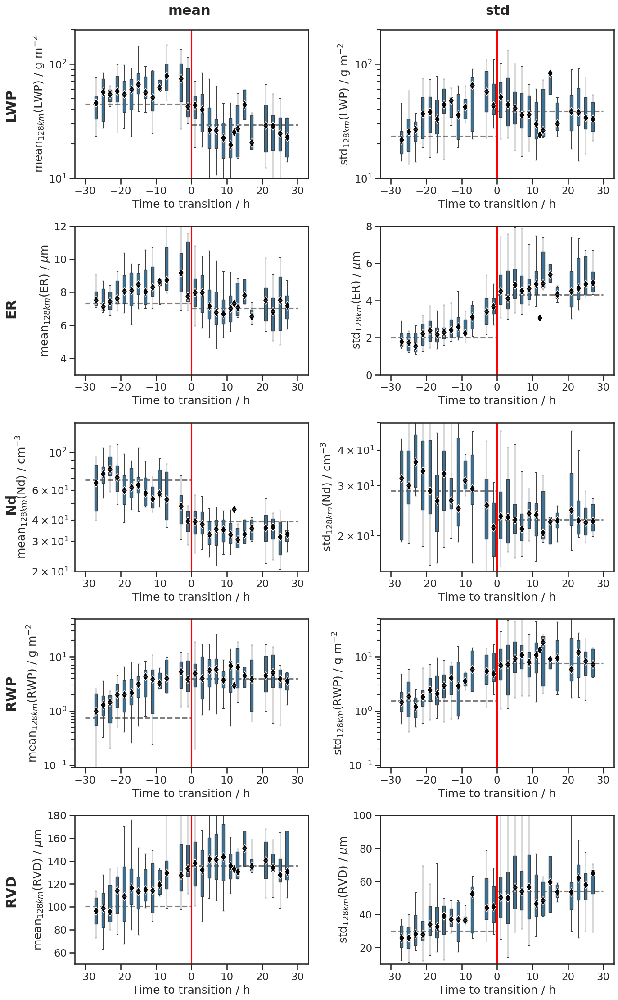

In [ ]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'lwp_std': {'factor': 1e3, 'y_label': 'std$_{128km}$(LWP) / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': 'mean$_{128km}$($r_e$) / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
    'ER_std': {'factor':1e6, 'y_label': 'std$_{128km}$($r_e$) / $\mu$m', 'y_lim': (0, 8), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': 'mean$_{128km}$($N_d$) / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'Nd_std': {'factor': 1e-6, 'y_label': 'std$_{128km}$($N_d$) / cm$^{-3}$', 'y_lim': (1.5e1, 5e1), 'y_scale': 'log'},
    'rwp': {'factor': 1e3, 'y_label': 'mean$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rwp_std': {'factor': 1e3, 'y_label': 'std$_{128km}$(RWP) / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'mean$_{128km}$($D_0$) / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_median_volume_diameter_std': {'factor':1e6, 'y_label': 'std$_{128km}$($D_0$) / $\mu$m', 'y_lim': (1e1, 1e2), 'y_scale': 'linear'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 5
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

axs[0].annotate('mean', xy=(0.4, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
axs[1].annotate('std', xy=(0.45, 1.1), xycoords='axes fraction', fontsize=22, fontweight='bold')
for idx, text in enumerate(['LWP','$r_e$','$N_d$','RWP','$D_0$']):
    axs[idx*2].annotate(text, xy=(-0.3, 0.4), xycoords='axes fraction', rotation=90, fontsize=22, fontweight='bold')
fig.tight_layout()
#plt.savefig('./figures/microphysics_vs_time.png', bbox_inches='tight')

<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_368554/3503352503.py:3: SyntaxWarning: invalid escape sequence '\m'
  'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
/tmp/ipykernel_368554/3503352503.py:6: SyntaxWarning: invalid escape sequence '\m'
  'rain_median_volume_diameter': {'factor':1e6, 'y_label': 'RVD / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jma

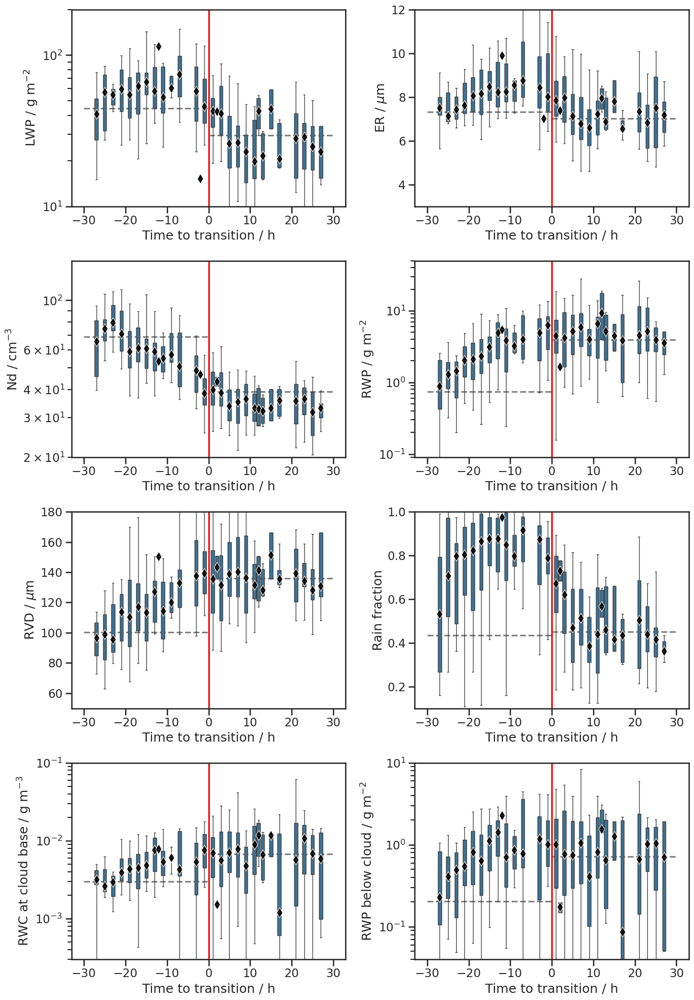

In [ ]:
plot_params = {
    'lwp': {'factor': 1e3, 'y_label': 'LWP / g m$^{-2}$', 'y_lim': (1e1, 2e2), 'y_scale': 'log'},
    'ER': {'factor':1e6, 'y_label': 'ER / $\mu$m', 'y_lim': (3, 12), 'y_scale': 'linear'},
    'Nd': {'factor': 1e-6, 'y_label': '$N_d$ / cm$^{-3}$', 'y_lim': (2e1, 1.5e2), 'y_scale': 'log'},
    'rwp': {'factor': 1e3, 'y_label': 'RWP / g m$^{-2}$', 'y_lim': (9e-2, 5e1), 'y_scale': 'log'},
    'rain_median_volume_diameter': {'factor':1e6, 'y_label': '$D_0$ / $\mu$m', 'y_lim': (5e1, 1.8e2), 'y_scale': 'linear'},
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'RWC at cloud base / g m$^{-3}$', 'y_lim': (3e-4, 1e-1), 'y_scale': 'log'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'RWP below cloud / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 4
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

    #ax2 = axs[i].twinx()
    #tmp = bt_co_concat[['transition_time_diff', var+'_std']].groupby('transition_time_diff').median()
    #sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var+'_std']*params['factor'], marker='o', color='green', s=40, linewidth=0, zorder=0, ax=axs[i])
    #plt.ylim(params['y_lim'])
    #plt.yscale(params['y_scale'])
    #plt.xlabel('Time to transition / h')
    #plt.ylabel('std(' + params['y_label'] + ')')
    #plt.axvline(0, color='red', linestyle='-')


fig.tight_layout()

/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff because variable transition_time_diff is not a coordinate. To create an index for transition_time_diff, please first call `.set_coords('transition_time_diff')` on this object.
  ds.expand_dims(dim_name, create_index_for_new_dim=create_index_for_new_dim)
/home/jmayer/miniconda3/envs/bt_env/lib/python3.13/site-packages/xarray/structure/concat.py:540: UserWarning: No index created for dimension transition_time_diff becaus

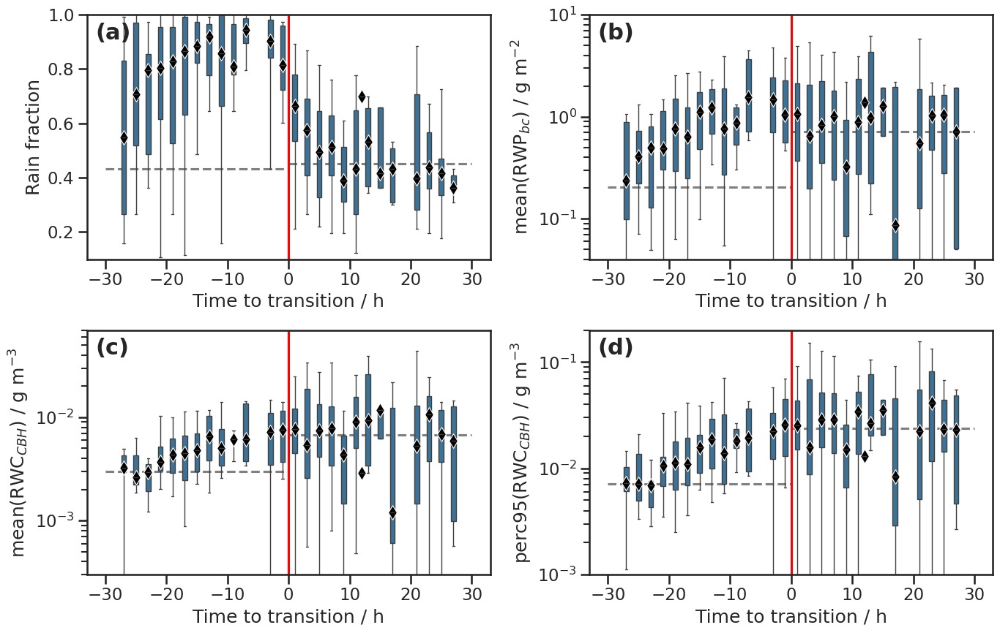

In [55]:
plot_params = {
    'rain_fraction': {'factor': 1, 'y_label': 'Rain fraction', 'y_lim': (0.1,1), 'y_scale': 'linear'},
    'rwp_subcloud': {'factor': 1e3, 'y_label': 'mean(RWP$_{bc}$) / g m$^{-2}$', 'y_lim': (4e-2, 1e1), 'y_scale': 'log'},
    'rwc_cbh': {'factor': 1e3, 'y_label': 'mean(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (3e-4, 7e-2), 'y_scale': 'log'},
    'rwc_cbh_perc95': {'factor': 1e3, 'y_label': 'perc95(RWC$_{CBH}$) / g m$^{-3}$', 'y_lim': (1e-3, 2e-1), 'y_scale': 'log'},
}

sns.set_context('talk', font_scale=1.)
sns.set_style('white')
plt.rcParams['xtick.bottom'] = True
plt.rcParams['xtick.top'] = False
plt.rcParams['ytick.left'] = True
plt.rcParams['ytick.right'] = False

nrows = 2
fig, axs = plt.subplots(nrows, 2, figsize=(14, nrows*4.5))
axs = axs.flatten()

for i, (var, params) in enumerate(plot_params.items()):
    plt.sca(axs[i])
    if var == 'no_plot':
        axs[i].axis('off')
        continue
    plt.hlines(acmcap_climatology_median[var].sel(cats=1)*params['factor'], xmin=-30, xmax=0, color='grey', linestyle='--')
    plt.hlines(acmcap_climatology_median[var].sel(cats=2)*params['factor'], xmin=0, xmax=30, color='grey', linestyle='--')
    sns.boxplot(data = bt_co_concat, x='transition_time_diff', y=bt_co_concat[var]*params['factor'], whis=(5, 95), native_scale=True, showfliers=False, saturation=0.6)
    tmp = bt_co_concat[['transition_time_diff', var]].groupby('transition_time_diff').median()
    sns.scatterplot(data=tmp, x='transition_time_diff', y=tmp[var]*params['factor'], color='black', marker='d', s=100, zorder=2)
    
    plt.yscale(params['y_scale'])
    plt.ylim(params['y_lim'])
    plt.xlabel('Time to transition / h')
    plt.ylabel(params['y_label'])
    plt.axvline(0, color='red', linestyle='-')

for idx, text in enumerate(['(a)','(b)','(c)','(d)']):
    axs[idx].annotate(text, xy=(0.02, 0.9), xycoords='axes fraction', fontsize=22, fontweight='bold')

fig.tight_layout()
plt.savefig('./figures/rain_details_vs_time.png', bbox_inches='tight')

## examples of transitioning clouds

In [ ]:
def plot_ACMCAP_MCOP_for_orbit(orbit, lat_min, lat_max):
    sys.path.append('./../../../ectools/')
    from ectools import ecio
    from ectools import colormaps
    sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
    import access_ec_on_maap as maap
    #from importlib import reload
    #reload(maap)

    dfscene = bt_co_concat.where((bt_co_concat.orbit == orbit) & (bt_co_concat.lat_mid >= lat_min) & (bt_co_concat.lat_mid <= lat_max), drop=True)
    time_startpoint = dfscene.time_startpoint.values[0]
    year = pd.to_datetime(time_startpoint).year
    month = pd.to_datetime(time_startpoint).month
    day = pd.to_datetime(time_startpoint).day
    region = 'SEP'
    transition_params=dfscene[['transition_time_diff','along_track_mid','cats','goes_cats','scene_id']].sel(timestep=0).groupby('scene_id').mean()

    # load ACMCAP
    try:
        filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
        ACMCAP = ecio.load_ACMCAP(filename)
    except IndexError:
        ACMCAP_list = maap.get_acmcap_via_maap(
                            frame=orbit[-1],
                            orbitNumber=orbit[:-1],
                            max_items=1,
                            )
        ACMCAP = ACMCAP_list[0][0]

    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

    # load MCOP
    MCOP_list = maap.get_mcop_via_maap(
            region=region, 
            frame=orbit[-1],
            orbitNumber=orbit[:-1],
            mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
            max_items=1)
        
    MCOP, _ = MCOP_list[0]

    MCOP = MCOP.assign_coords(
        {
        'along_track': (
            ["along_track"],
            MCOP['along_track'].data,
            MCOP['along_track'].attrs
            ),
        'across_track': (
            ['across_track'],
            MCOP['across_track'].data,
            MCOP['across_track'].attrs
            )
        })
    along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
    along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
    MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
    MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

    # load CCD
    CCD_list = maap.get_ccd_via_maap(
                    frame=orbit[-1],
                    orbitNumber=orbit[:-1],
                    max_items=1,
                    )
    CCD = CCD_list[0][0]
    CCD = CCD.where((CCD.latitude > lat_min) & (CCD.latitude < lat_max), drop=True)
    CCD = CCD.assign_coords(height_coord=("CPR_height", CCD.height.isel(along_track=0).data))
    CCD = CCD.swap_dims({'CPR_height': 'height_coord'})
    CCD = CCD.where(CCD.height_coord > -500, drop=True)

    # plot
    sns.set_context('talk')
    length_along_track = len(ACMCAP.along_track)
    figsize = (length_along_track/112*7, 9)
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
    ACMCAP.liquid_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-6, vmax=1e-3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC (kg m$^{-3}$)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    title = f'{orbit}, lat:{np.round(lat_min, 2)}-{np.round(lat_max, 2)}'
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_water_path.T.plot(ax=ax, cmap='viridis', vmin=1e-2, vmax=1e0, norm=LogNorm(), add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP liquid water path')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    fig, axs = plt.subplots(2,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 3]})
    ACMCAP.liquid_effective_radius.T.plot(ax=axs[0], ylim=(0,3000), vmin=5e-6, vmax=2e-5, cmap='turbo', cbar_kwargs={'label': '$r_e$ (m)'})
    #dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
    axs[0].set_title(title)
    ax = axs[1]
    MCOP2.cloud_effective_radius.T.plot(ax=ax, cmap='viridis', vmin=5e-6, vmax=2e-5, add_colorbar=True)
    ax.axhline(284, color='k', linestyle='--', lw=2)
    ax.set_title('MCOP effective radius')
    for i,t in enumerate(transition_params["transition_time_diff"].values):
        ax.annotate(f'{t:.2f}', xy=(transition_params["along_track_mid"].values[i], 290), xycoords='data', fontsize=12, color='red')
        ax.annotate(f'{transition_params["cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 275), xycoords='data', fontsize=12, color='black')
        ax.annotate(f'{transition_params["goes_cats"].values[i]}', xy=(transition_params["along_track_mid"].values[i], 265), xycoords='data', fontsize=12, color='blue')
    fig.tight_layout()
    plt.show()

    sns.set_context('talk')
    figsize = (length_along_track/112*7, 12)
    fig, axs = plt.subplots(5,1, figsize=figsize, gridspec_kw={'height_ratios': [1, 1, 1, 1, 1]})
    ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC (kg m$^{-3}$)'})
    mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
    axs[0].annotate(fr'{mean_RWP:.1f}g/m$^{2}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    axs[0].set_title(f'{orbit}, lat:{lat_min.round(2)}-{lat_max.round(2)}')
    ACMCAP.rain_median_volume_diameter.T.plot(ax=axs[1], ylim=(0,3000), vmin=1e-5, vmax=1e-3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$D_0$ (m)'})
    mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
    axs[1].annotate(fr'{mean_RVD:.1f}$\mu$m', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    ACMCAP.rain_normalized_number_concentration.T.plot(ax=axs[2], ylim=(0,3000), vmin=1e7, vmax=1e10, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'N$_{R}$ (m$^{-3}$)'})
    mean_RNC = (ACMCAP.rain_normalized_number_concentration.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e-6
    axs[2].annotate(fr'{mean_RNC:.1f}cm$^{{-3}}$', xy=(0.8,0.85), xycoords='axes fraction', fontsize=15)
    #ACMCAP.CPR_reflectivity_factor.T.plot(ax=axs[3], ylim=(0,3000), vmin=-40, vmax=0, cmap='turbo', cbar_kwargs={'label': 'Refl. (dBZ)'})
    CFMR.reflectivity_no_attenuation_correction.T.plot(ax=axs[3], cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. (dBZ)'})
    (CCD['doppler_velocity_best_estimate'] - CCD['sedimentation_velocity_best_estimate']).T.plot(ax=axs[4], cmap='RdBu', vmin=-2, vmax=2, ylim=(0,3000), cbar_kwargs={'label': 'w (m/s)'})
    fig.tight_layout()
    plt.show()

In [194]:
ds_23h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -23), drop=True)
ds_13h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -13), drop=True)
ds_3h_before_trans = bt_co_concat.where((bt_co_concat.transition_flag==1) & (bt_co_concat.transition_time_diff == -3), drop=True)

------------------ 3h before transition ------------------
Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766E.h5
Orbit: 06766E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/06/ECA_EXBA_MSI_COP_2A_20250806T193156Z_20250806T210536Z_06766

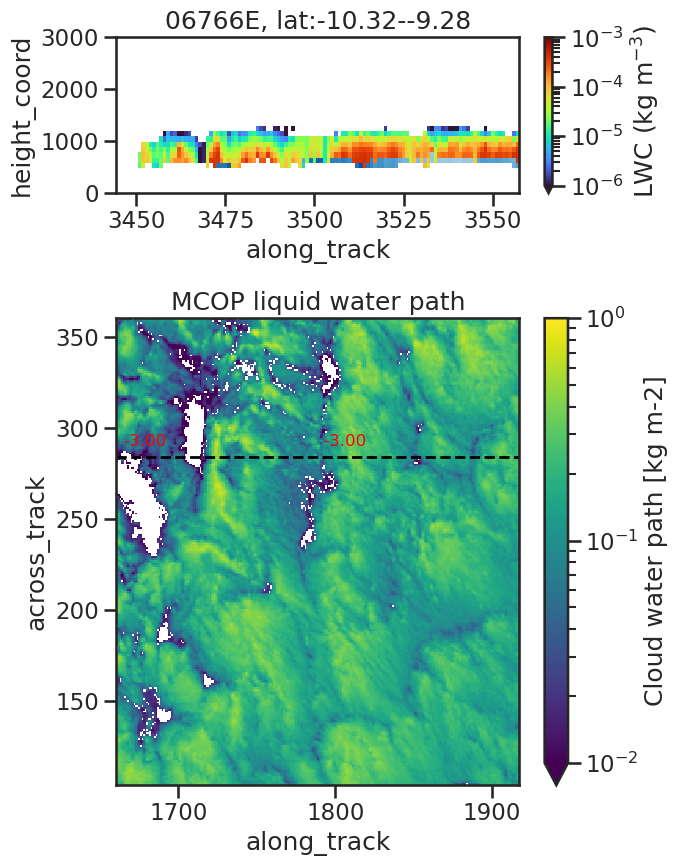

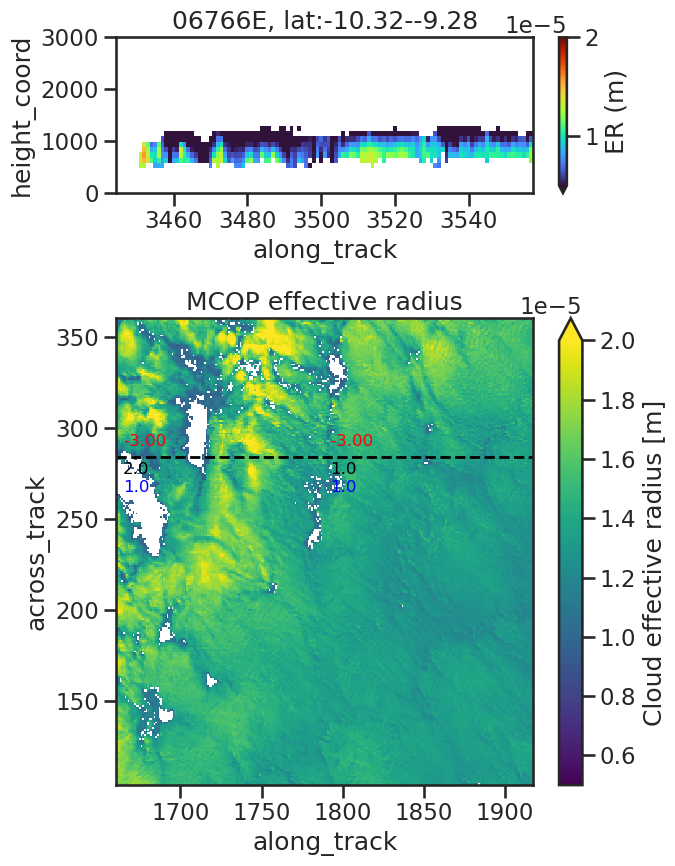

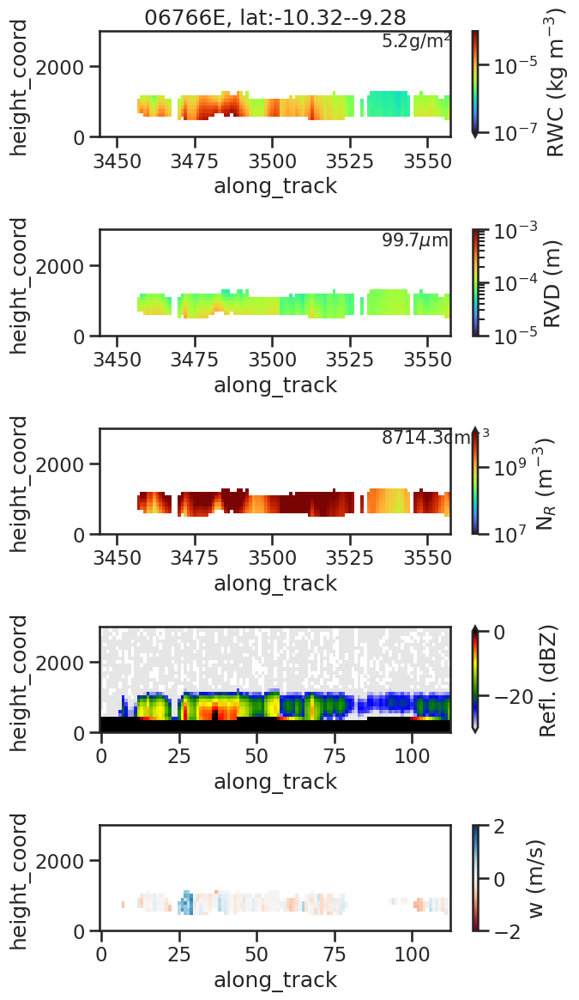

Selecting frame from 5 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E.h5
Orbit: 06299E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/07/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_06299E/ECA_EXBA_MSI_COP_2A_20250707T191345Z_20250930T091859Z_062

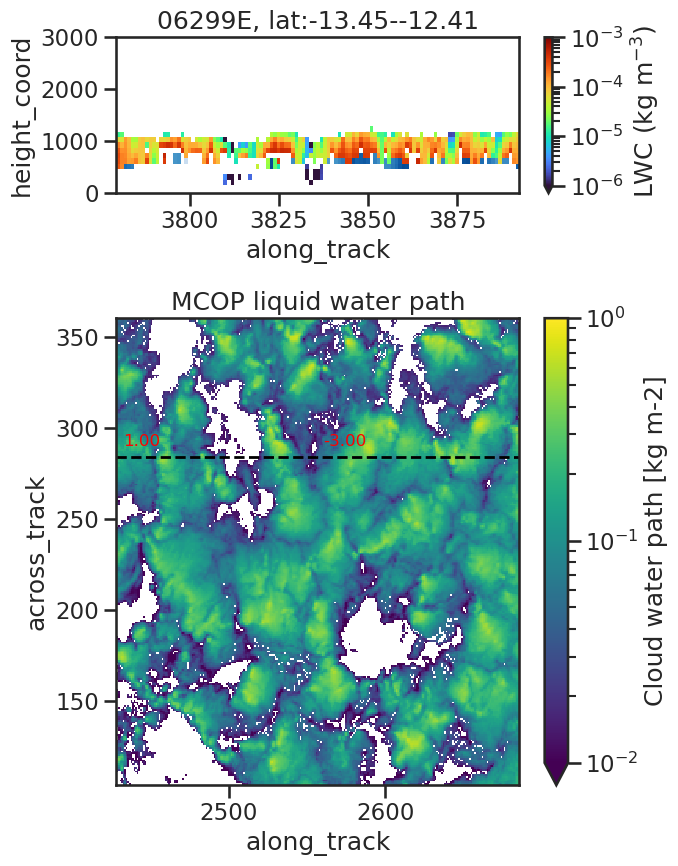

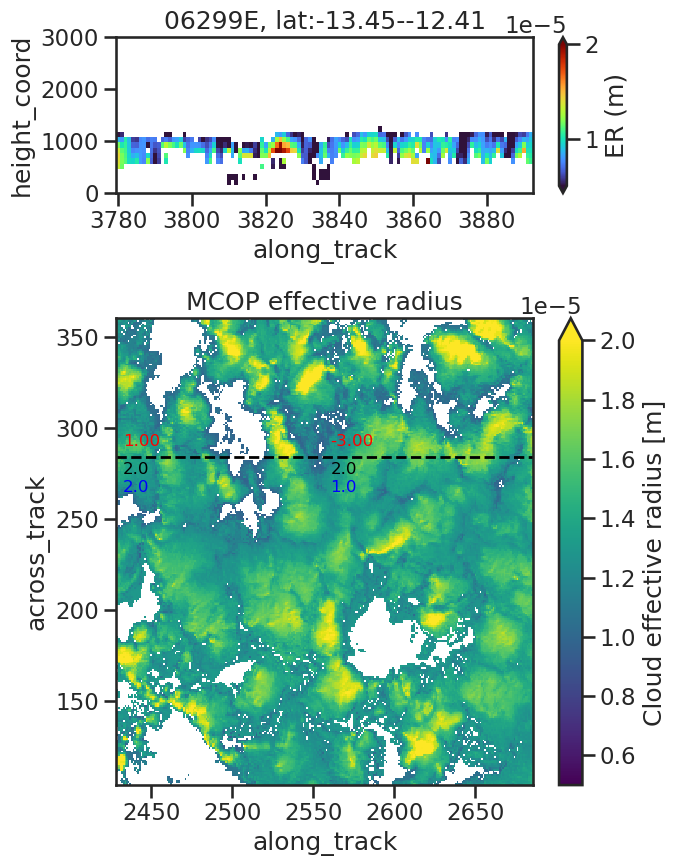

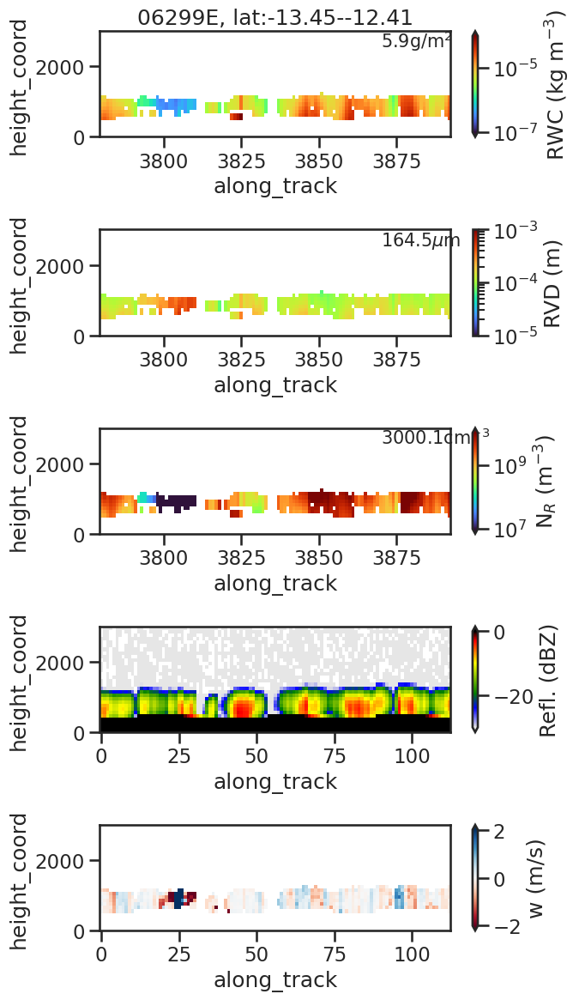

Selecting frame from 7 to 4875
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E.h5
Orbit: 06517E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/21/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_06517E/ECA_EXBA_MSI_COP_2A_20250721T192827Z_20250721T205834Z_065

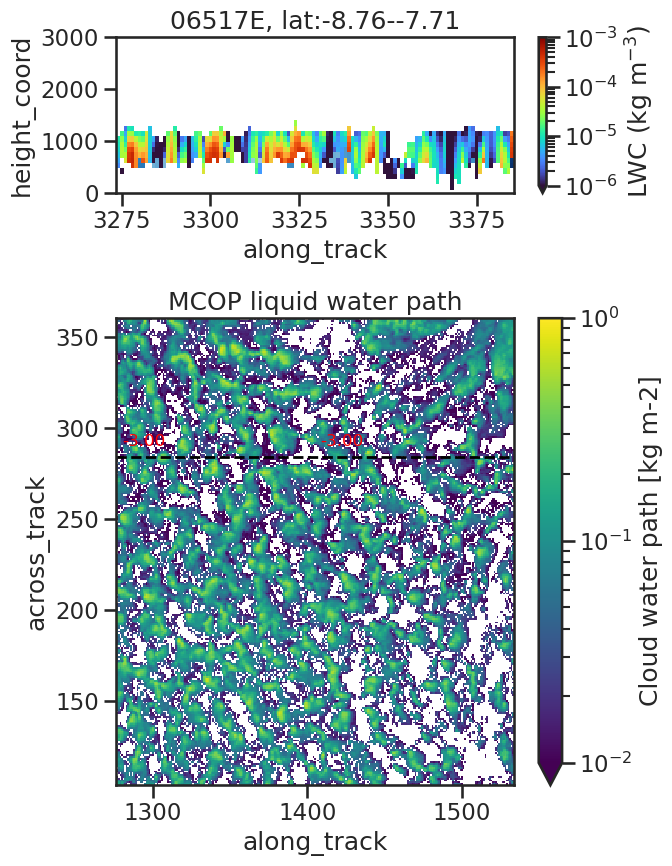

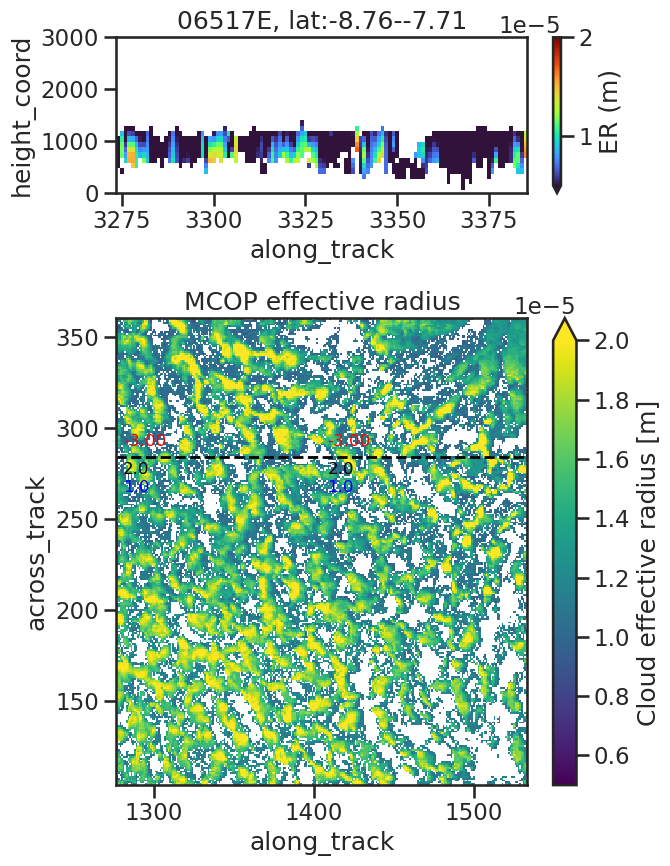

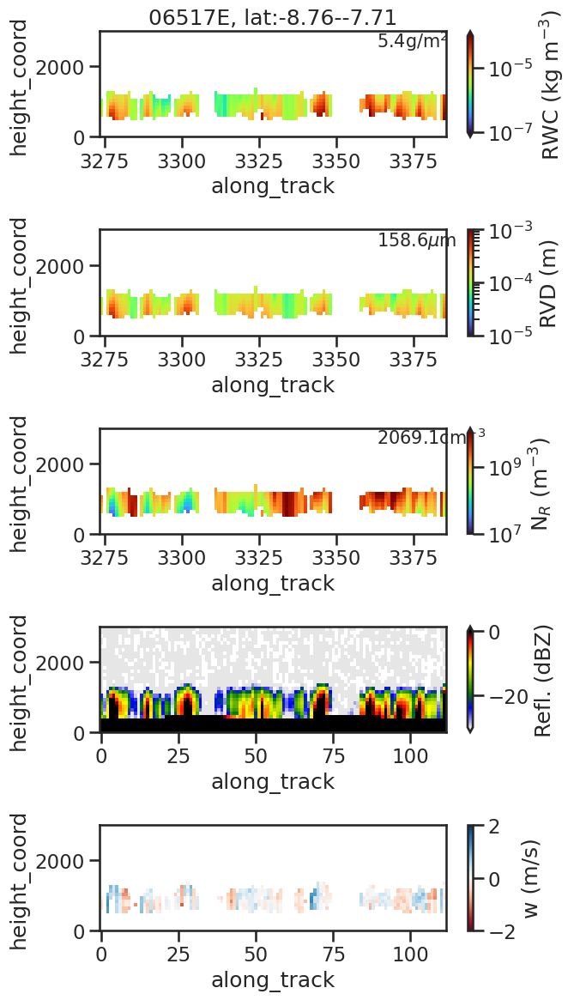

------------------ 13h before transition ------------------
Selecting frame from 6 to 4874
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_06159E.h5
Orbit: 06159E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/28/ECA_EXBA_MSI_COP_2A_20250628T191749Z_20250929T145126Z_0615

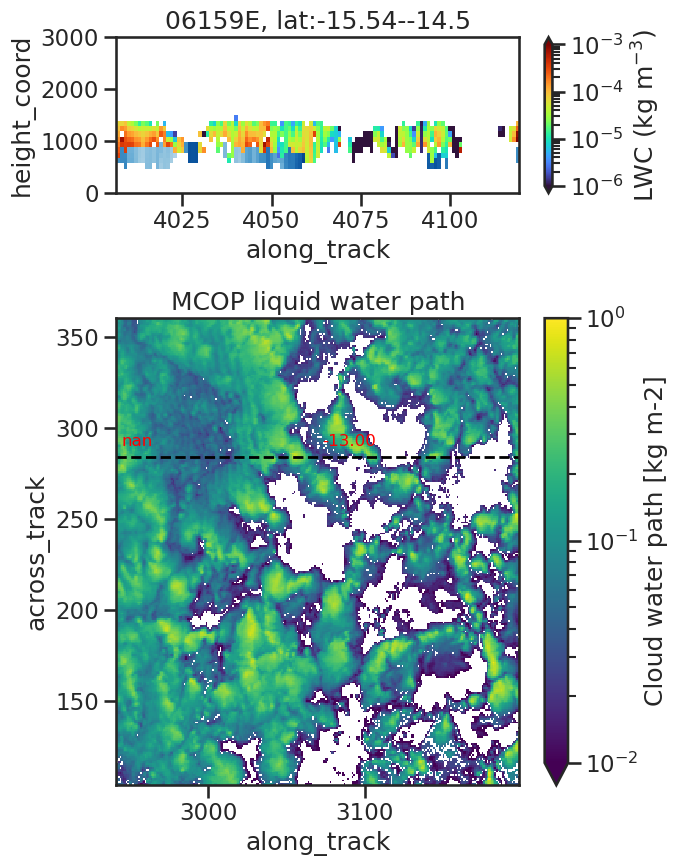

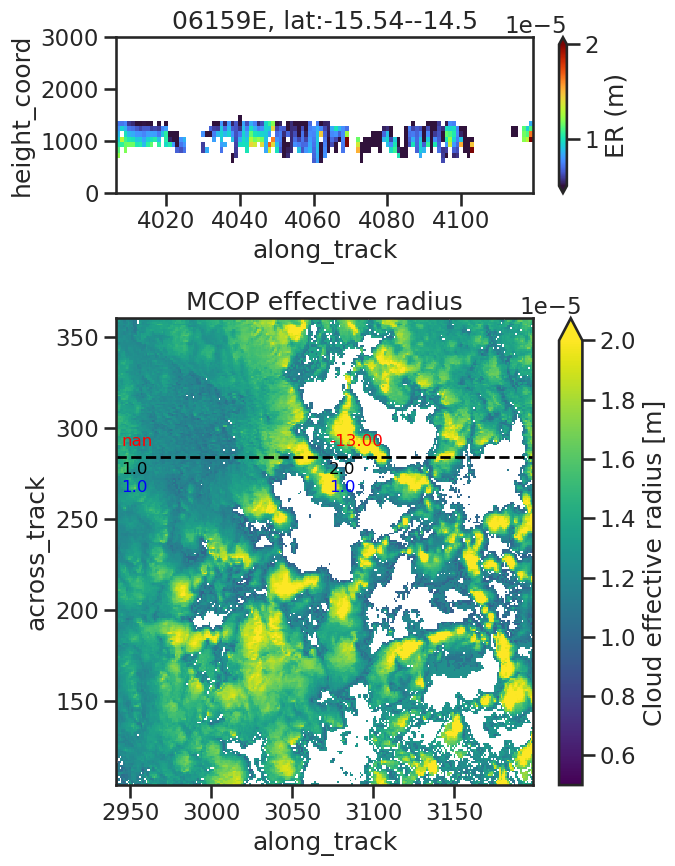

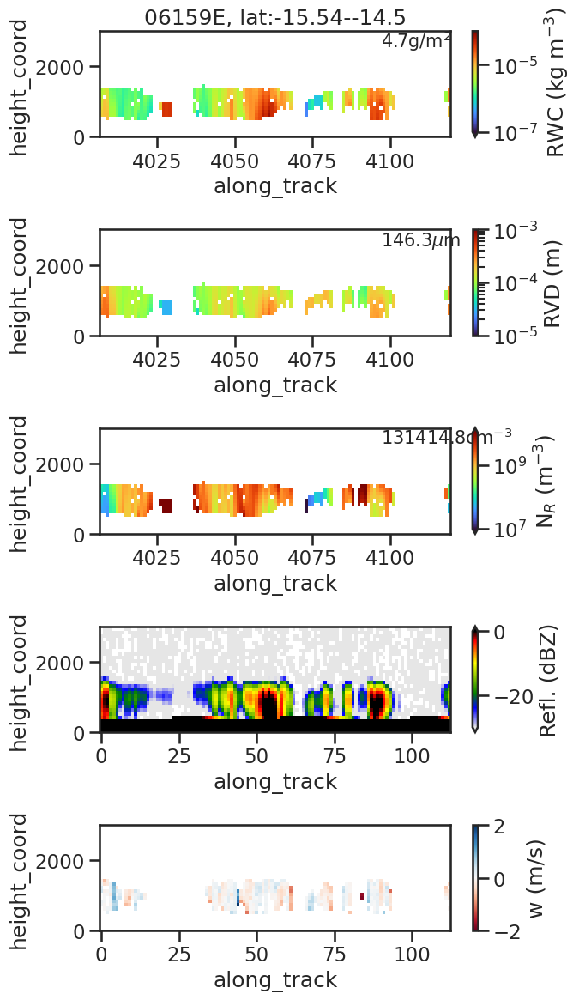

Selecting frame from 7 to 4876
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E.h5
Orbit: 06361E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/07/11/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_06361E/ECA_EXBA_MSI_COP_2A_20250711T185132Z_20250711T202021Z_063

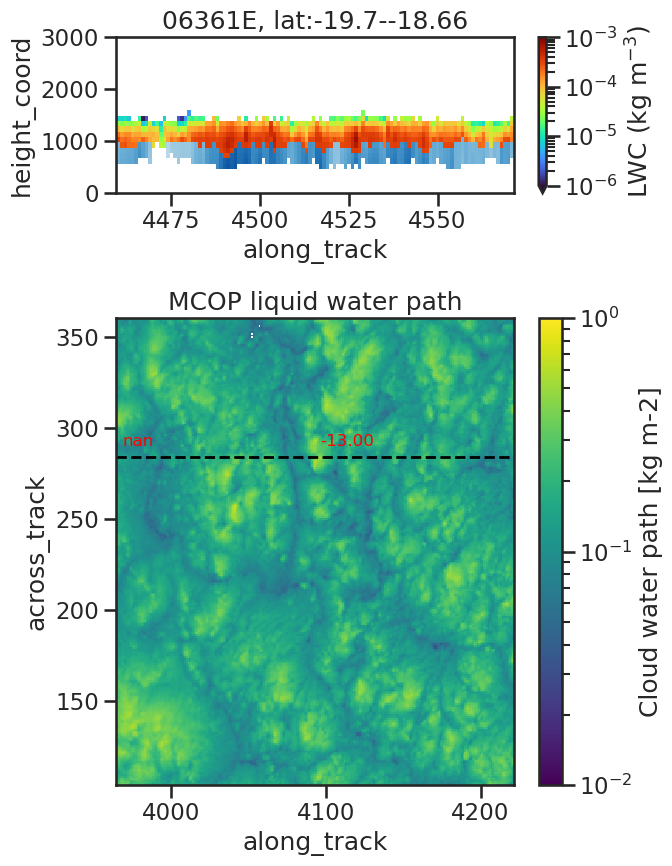

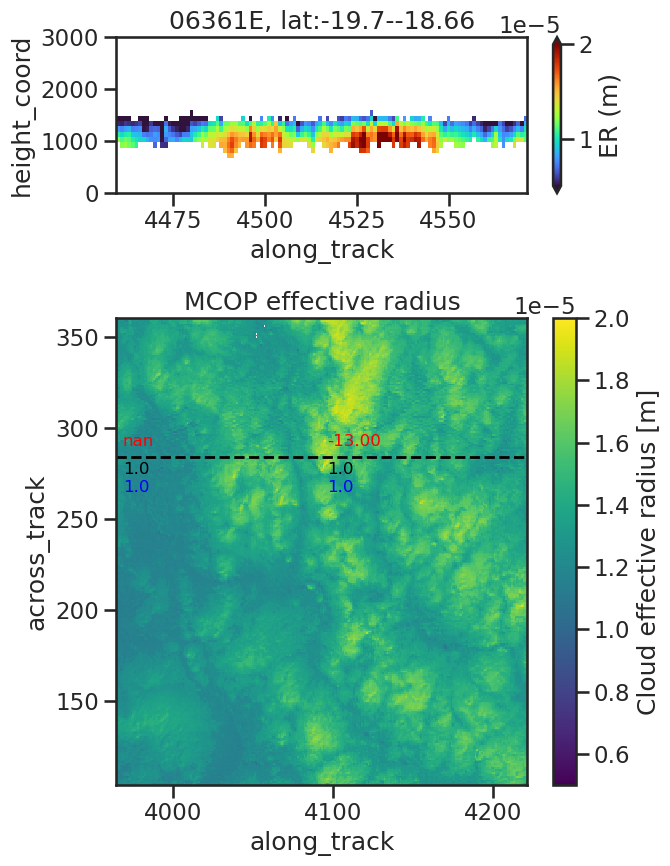

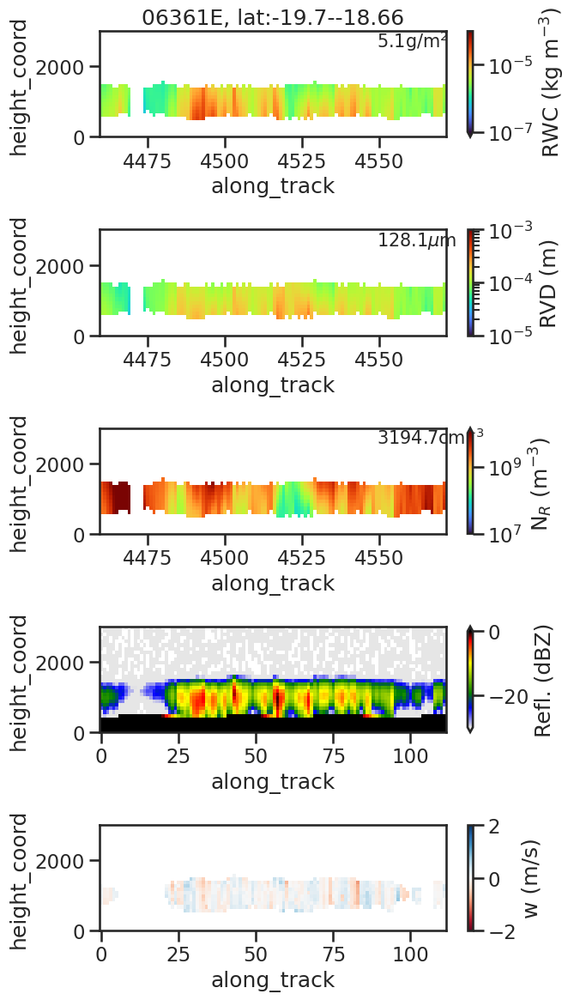

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E.h5
Orbit: 06050E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/21/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_06050E/ECA_EXBA_MSI_COP_2A_20250621T191023Z_20250929T150416Z_060

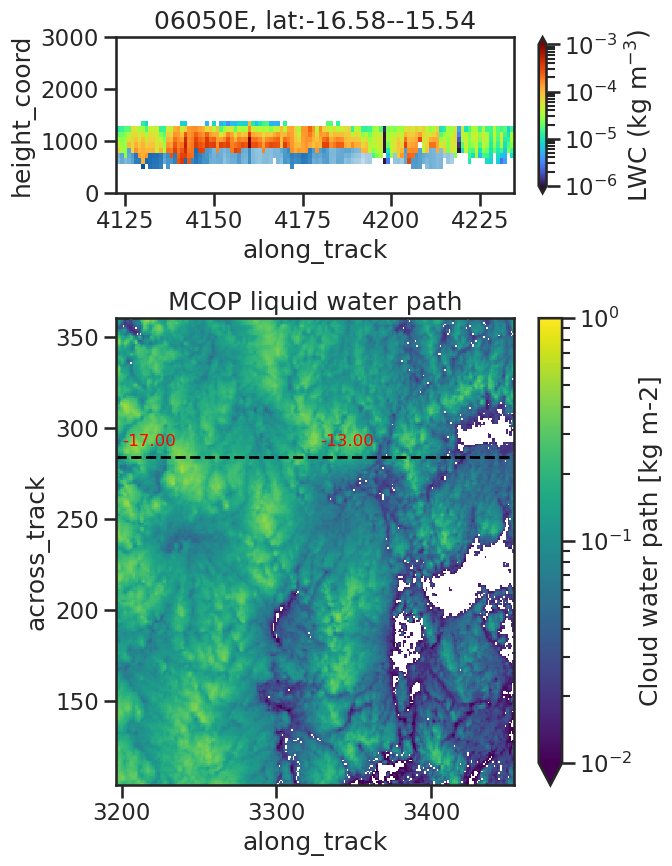

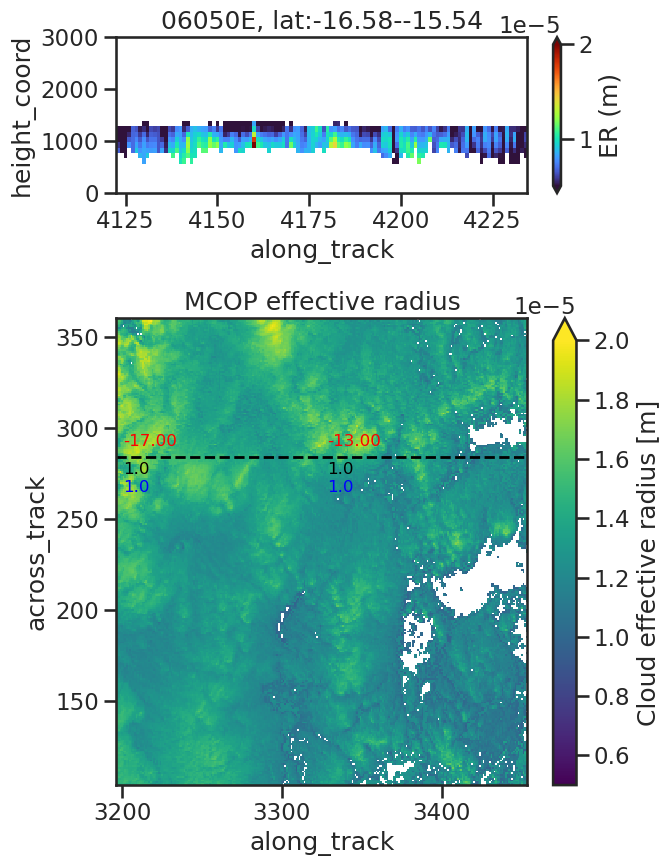

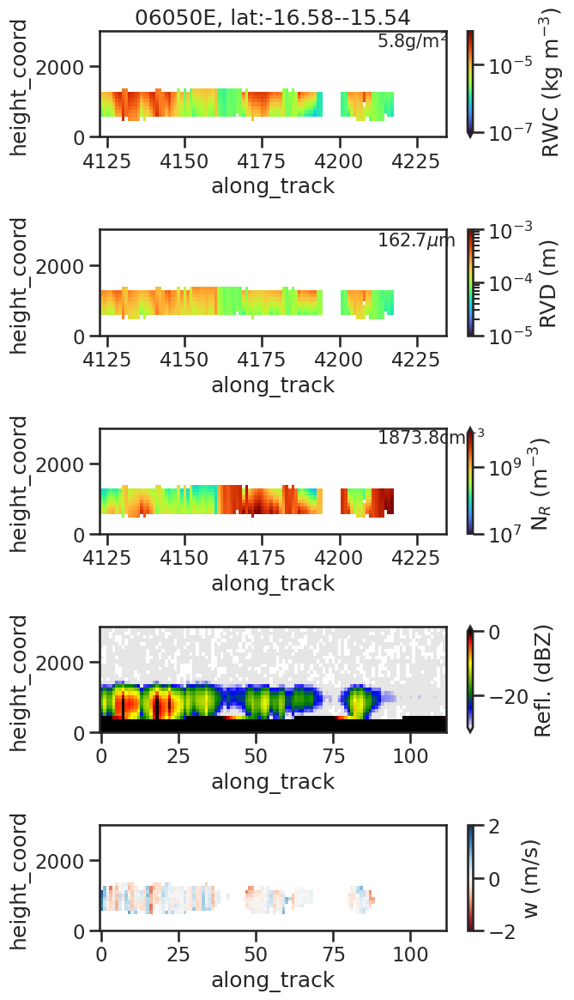

------------------ 23h before transition ------------------
Selecting frame from 7 to 4879
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_01071E.h5
Orbit: 01071E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/05/ECA_EXBA_MSI_COP_2A_20240805T192025Z_20250904T103834Z_0107

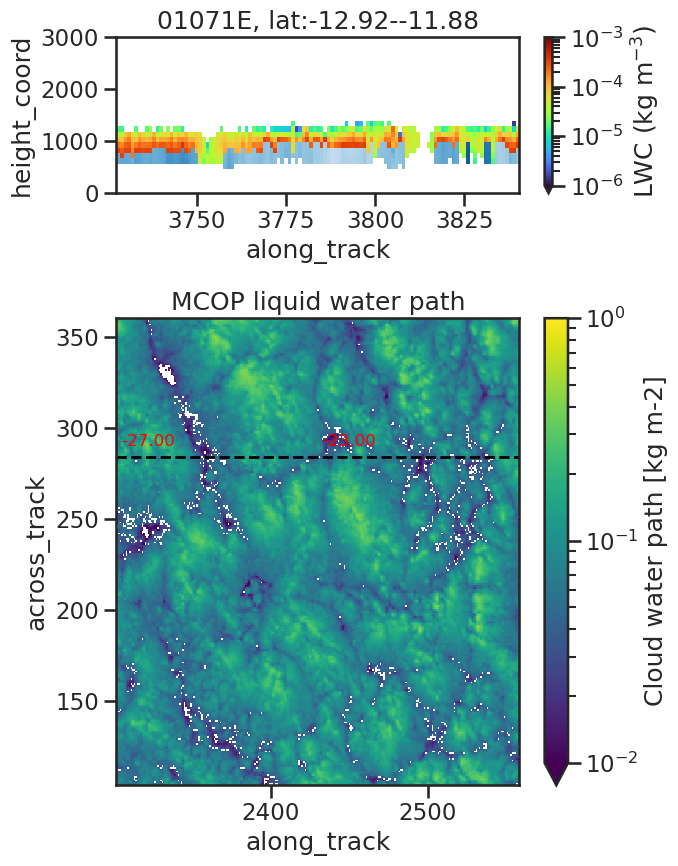

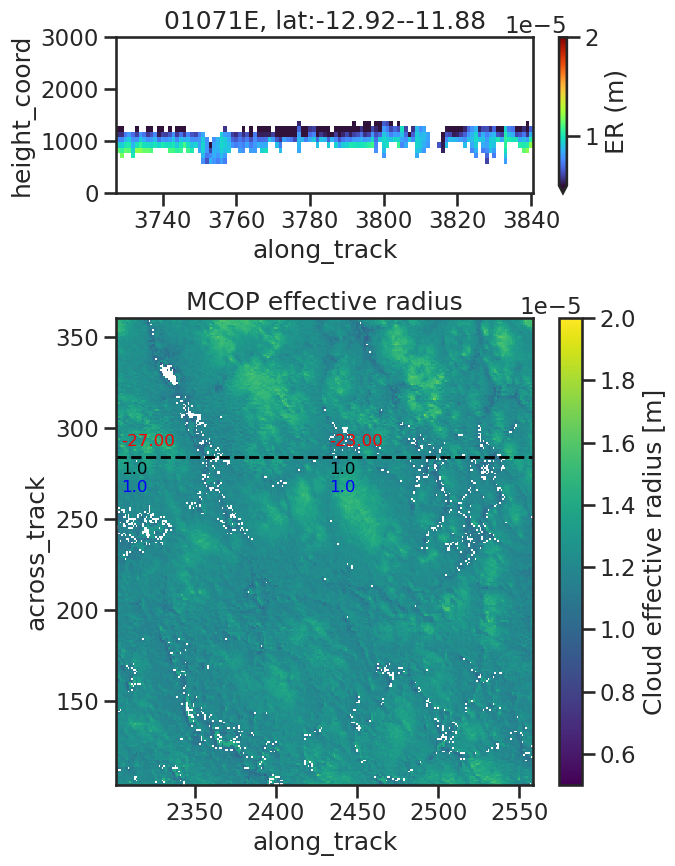

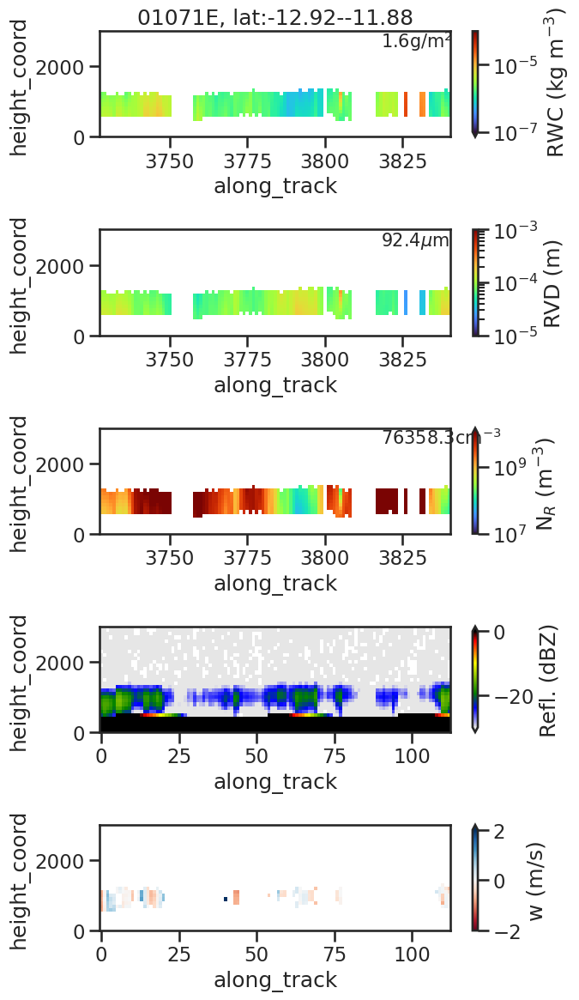

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E.h5
Orbit: 06828E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/10/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_06828E/ECA_EXBA_MSI_COP_2A_20250810T190948Z_20250810T203753Z_068

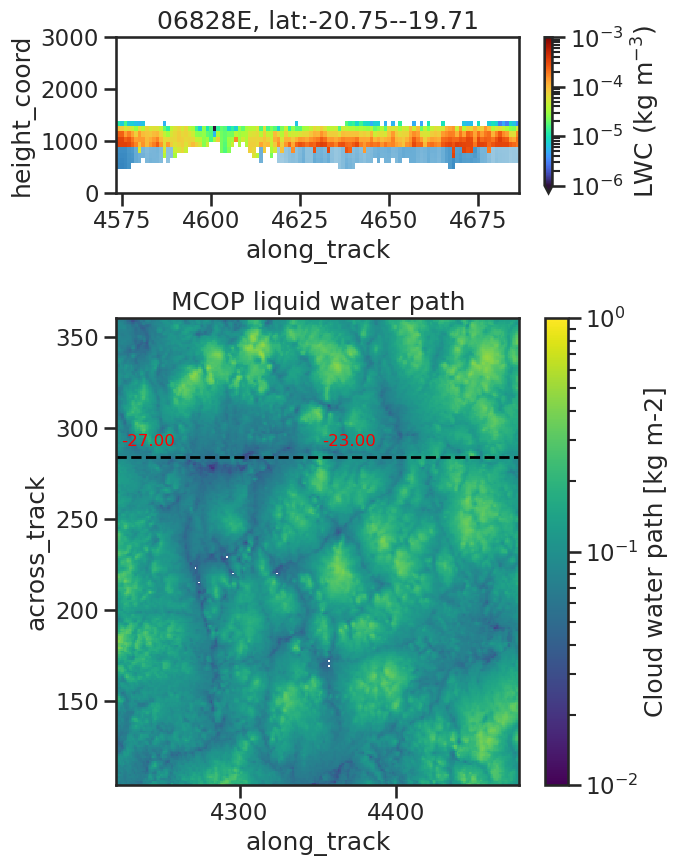

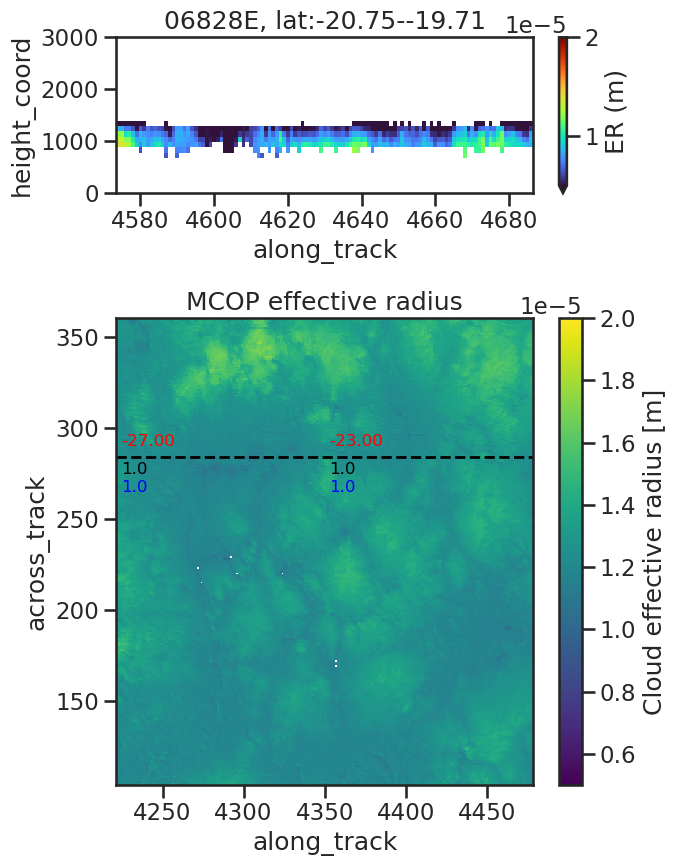

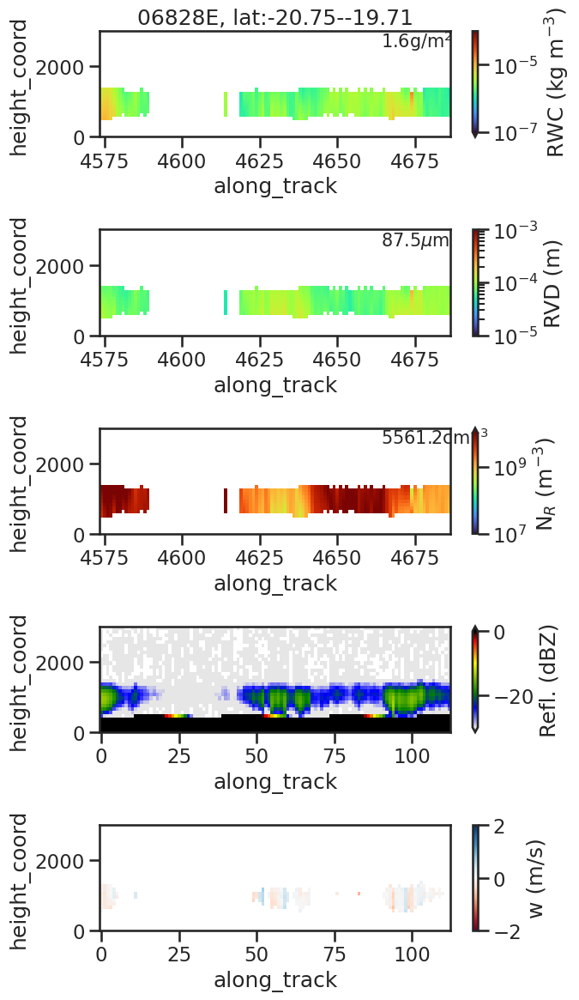

Selecting frame from 7 to 4875
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E.h5
Orbit: 07077E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/08/26/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_07077E/ECA_EXBA_MSI_COP_2A_20250826T191322Z_20250826T204143Z_070

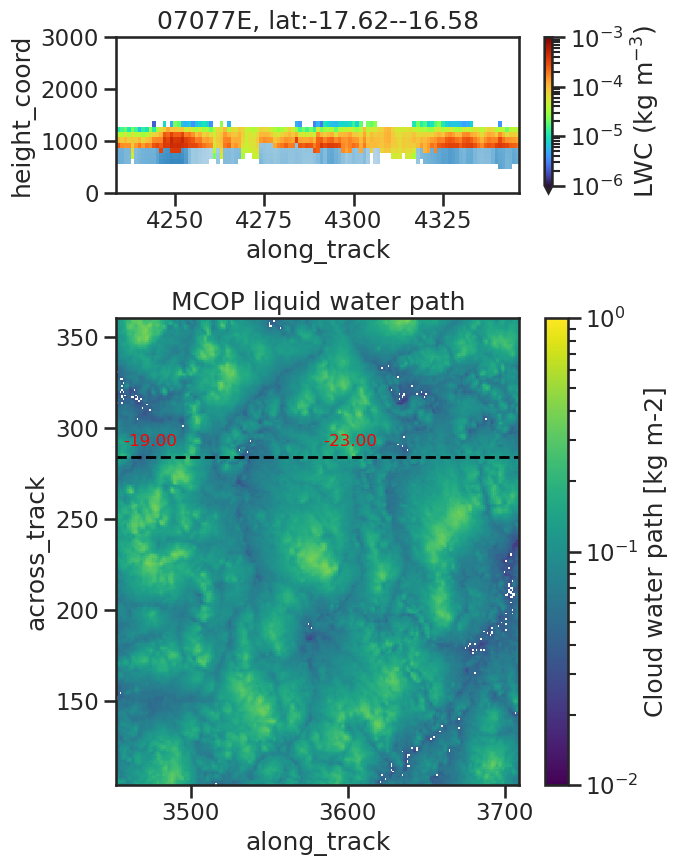

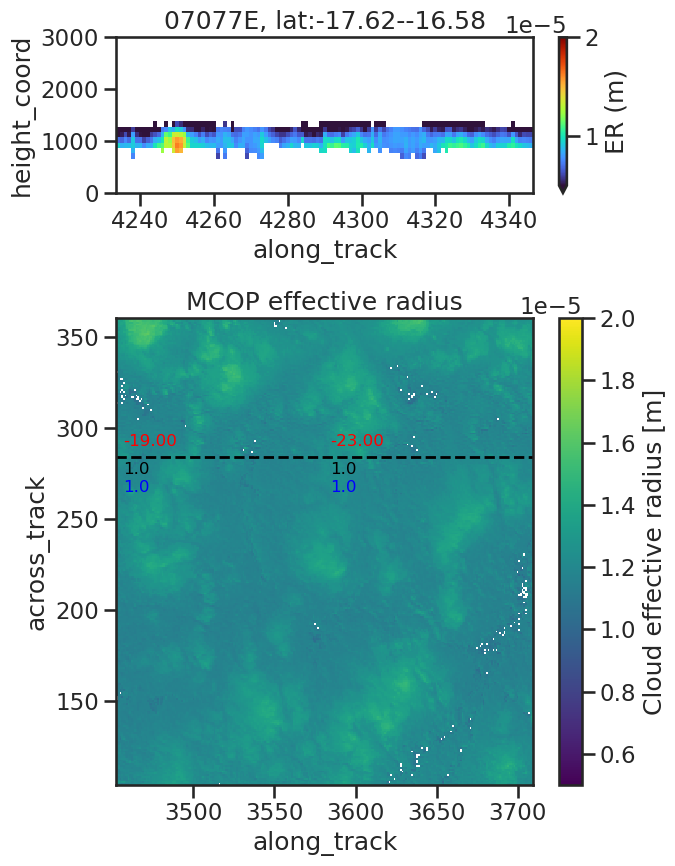

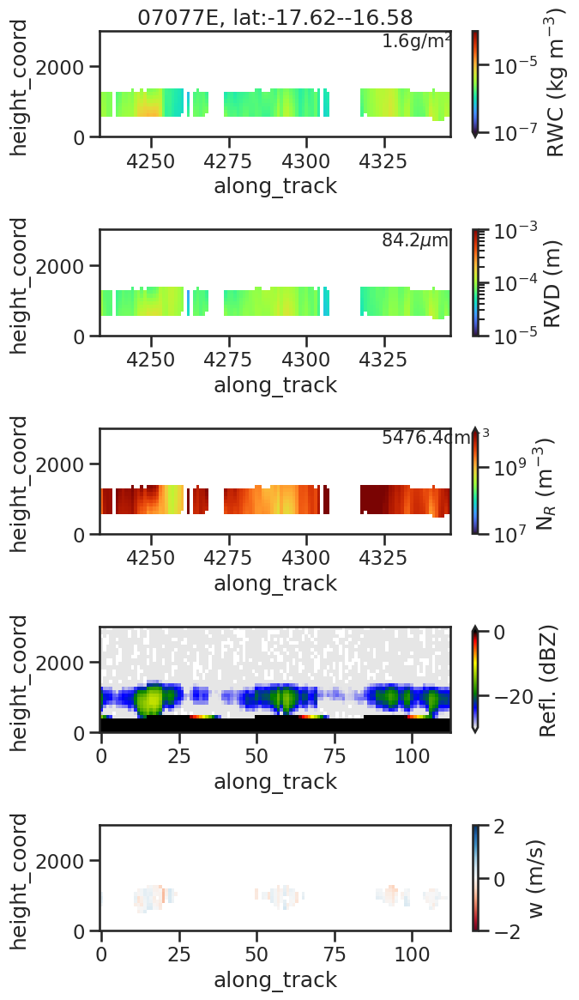

In [212]:
print('------------------ 3h before transition ------------------')
ds_3h_before_trans['rwp_diff_to_median'] = np.abs(ds_3h_before_trans['rwp'].median() - ds_3h_before_trans['rwp'])
ds_3h_before_trans = ds_3h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_3h_before_trans_i = ds_3h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_3h_before_trans_i['orbit'].values), ds_3h_before_trans_i['lat_min'].values, ds_3h_before_trans_i['lat_max'].values)

print('------------------ 13h before transition ------------------')
ds_13h_before_trans['rwp_diff_to_median'] = np.abs(ds_13h_before_trans['rwp'].median() - ds_13h_before_trans['rwp'])
ds_13h_before_trans = ds_13h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_13h_before_trans_i = ds_13h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_13h_before_trans_i['orbit'].values), ds_13h_before_trans_i['lat_min'].values, ds_13h_before_trans_i['lat_max'].values)

print('------------------ 23h before transition ------------------')
ds_23h_before_trans['rwp_diff_to_median'] = np.abs(ds_23h_before_trans['rwp'].median() - ds_23h_before_trans['rwp'])
ds_23h_before_trans = ds_23h_before_trans.sortby('rwp_diff_to_median')
for i in range(3):
    ds_23h_before_trans_i = ds_23h_before_trans.isel(time_startpoint=i)
    plot_ACMCAP_MCOP_for_orbit(str(ds_23h_before_trans_i['orbit'].values), ds_23h_before_trans_i['lat_min'].values, ds_23h_before_trans_i['lat_max'].values)

In [26]:
ds_at_transition = bt_co_concat.where(np.abs(bt_co_concat.transition_time_diff) <= 1, drop=True)

# look for low LWP clouds at transition - what is going on here?
ds_at_transition = ds_at_transition.where((ds_at_transition.cats == 1), drop=True)
np.unique(ds_at_transition.orbit.values)

array(['01351E', '01460E', '05630E', '05708E', '06019E', '06439E',
       '06517E', '06766E', '06906E', '07046E', '07373E'], dtype=object)

In [46]:
ds_before_transition = bt_co_concat.where((bt_co_concat.transition_time_diff <= -20) & (bt_co_concat.transition_time_diff >= -24), drop=True)
np.unique(ds_before_transition.orbit.values)

array(['01009E', '01071E', '01211E', '01242E', '01351E', '01382E',
       '01553E', '01631E', '01709E', '01740E', '01833E', '01942E',
       '02160E', '02238E', '02409E', '06268E', '06408E', '06470E',
       '06517E', '06766E', '06828E', '07077E', '07108E', '07155E',
       '07279E', '07326E', '07637E'], dtype=object)

In [55]:
non_trans_high_rwp = bt_non_trans_c.where(bt_non_trans_c.rwp > 3e-3, drop=True)
np.unique(non_trans_high_rwp.orbit.values)

array(['01102E', '01942E', '06190E', '06268E', '06408E', '06548E',
       '06579E', '06766E', '06828E', '07933E'], dtype=object)

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E.h5
Orbit: 03203E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/12/20/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_03203E/ECA_EXBA_MSI_COP_2A_20241220T195735Z_20250910T215115Z_032

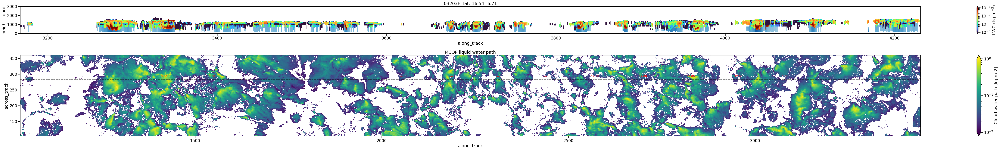

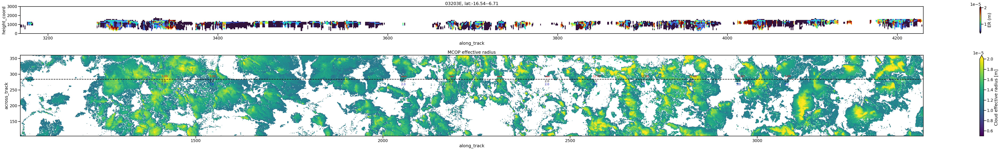

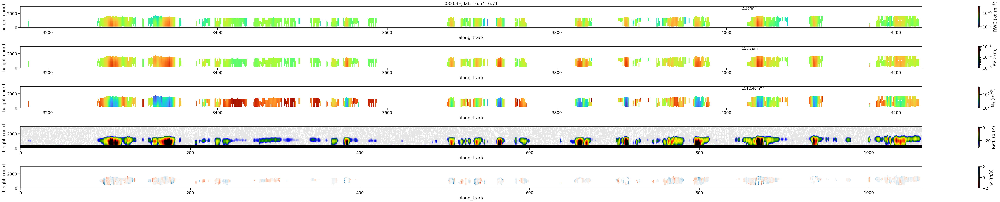

In [ ]:
orbit = '03203E'
ds_orbit = bt_co_concat.where(bt_co_concat.orbit == orbit, drop=True)
lat_min = ds_orbit.lat_min.min().values
lat_max = ds_orbit.lat_max.max().values
plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)

In [27]:
for i,orbit in enumerate(np.unique(ds_before_transition.orbit.values)[:5]):
    ds_before_transition_orbit = ds_before_transition.where(ds_before_transition.orbit == orbit, drop=True)
    lat_min = ds_before_transition_orbit.lat_min.min().values
    lat_max = ds_before_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

NameError: name 'ds_before_transition' is not defined

In [27]:
9.81 * 2.5e6 / (1.2 * 800 * 1004 * 300) *1e2 * 3600

30534.113545816734

In [ ]:
for i,orbit in enumerate(np.unique(non_trans_high_rwp.orbit.values)):
    non_trans_high_rwp_orbit = non_trans_high_rwp.where(non_trans_high_rwp.orbit == orbit, drop=True)
    lat_min = non_trans_high_rwp_orbit.lat_min.min().values
    lat_max = non_trans_high_rwp_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

Selecting frame from 8 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E.h5
Orbit: 01351E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/23/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_01351E/ECA_EXBA_MSI_COP_2A_20240823T192509Z_20250904T101701Z_013

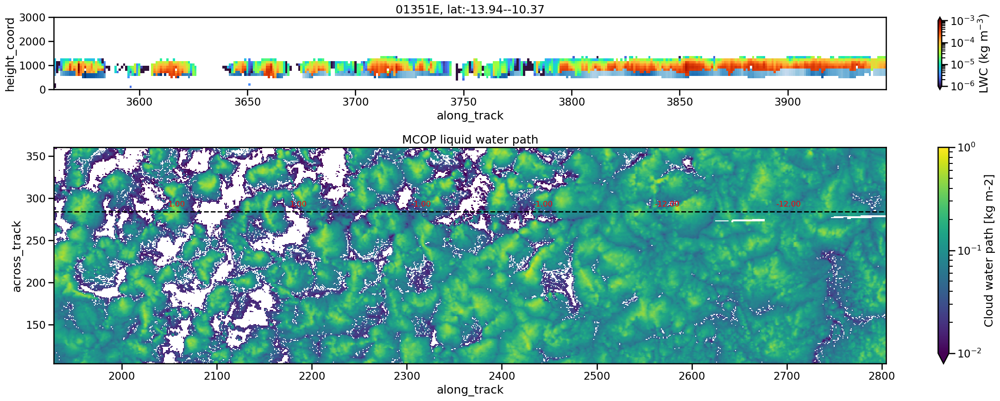

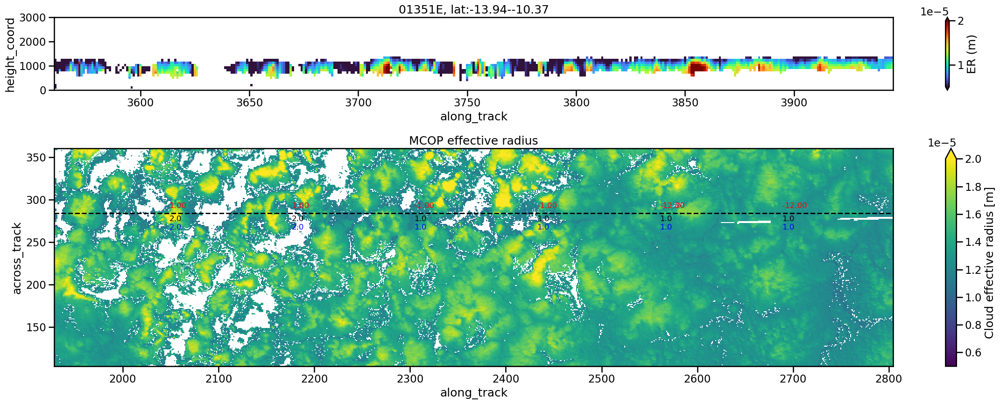

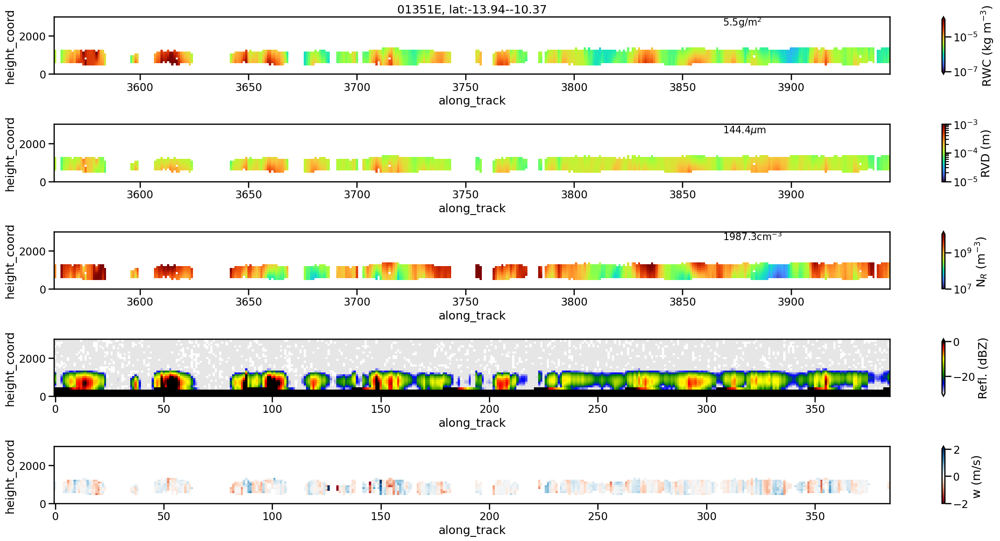

Selecting frame from 9 to 4873
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E.h5
Orbit: 01460E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2024/08/30/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_01460E/ECA_EXBA_MSI_COP_2A_20240830T193307Z_20250904T094302Z_014

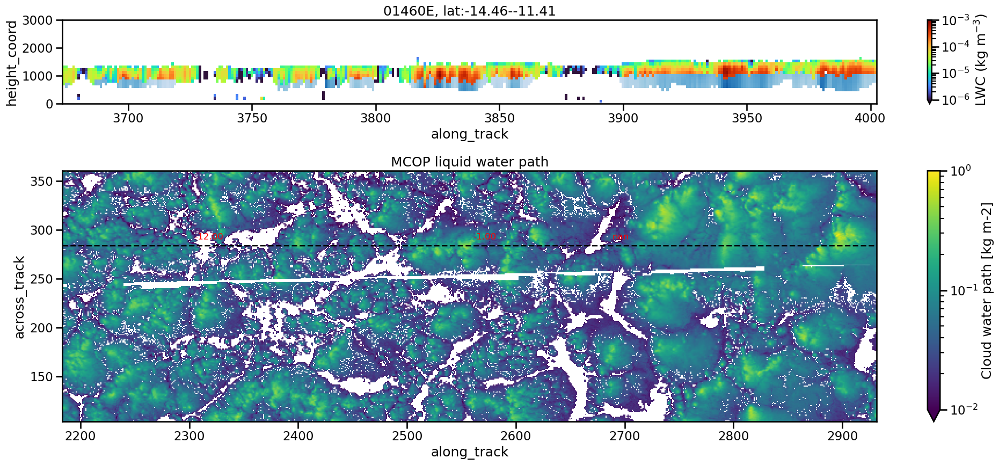

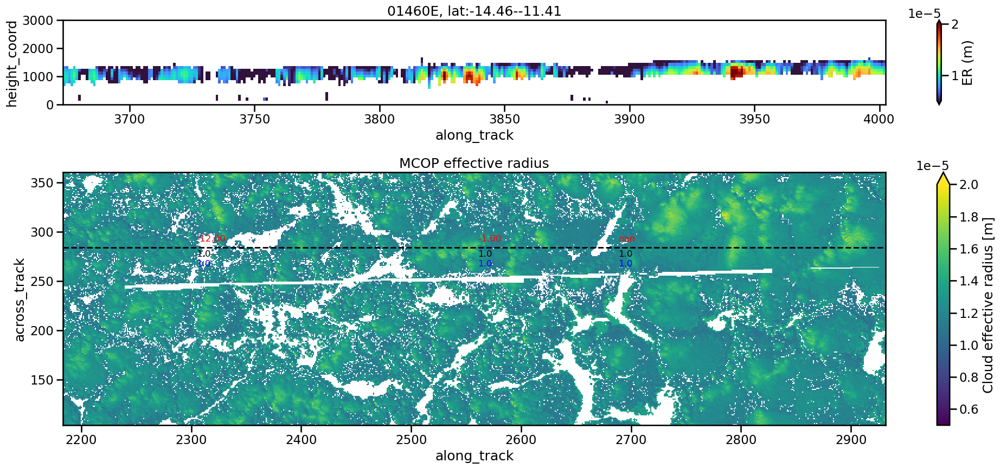

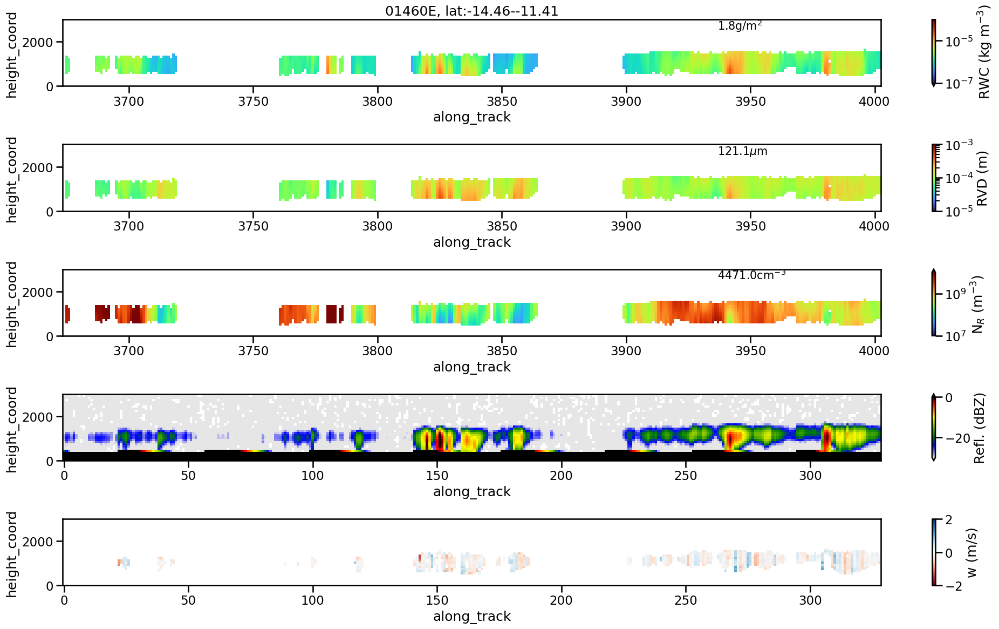

Selecting frame from 9 to 4876
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E.h5
Orbit: 05630E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/25/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_05630E/ECA_EXBA_MSI_COP_2A_20250525T192147Z_20250917T143039Z_056

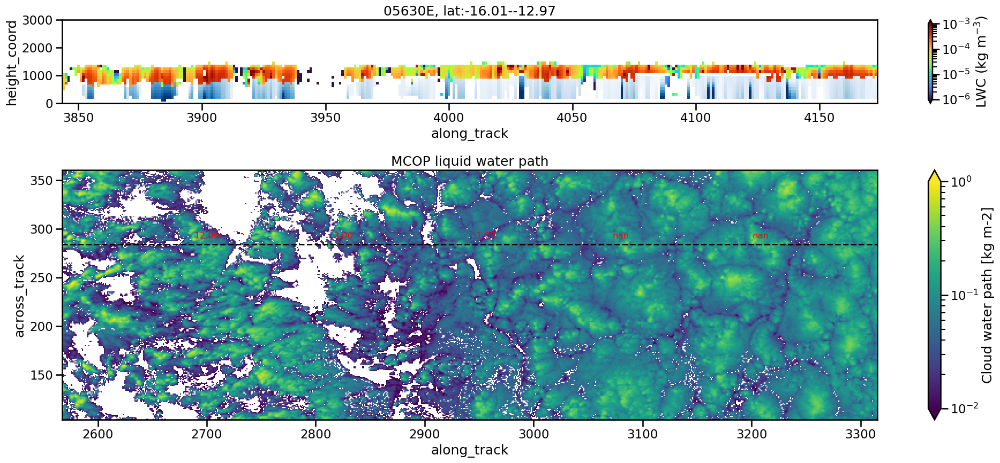

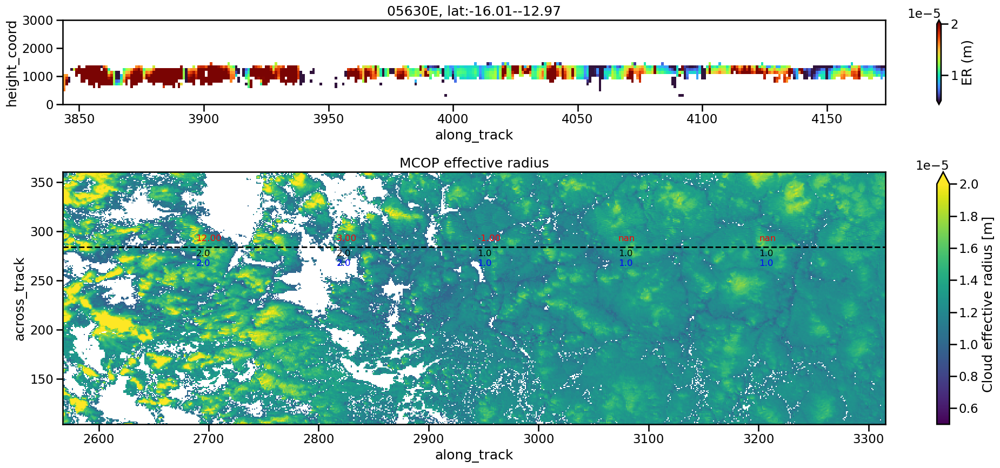

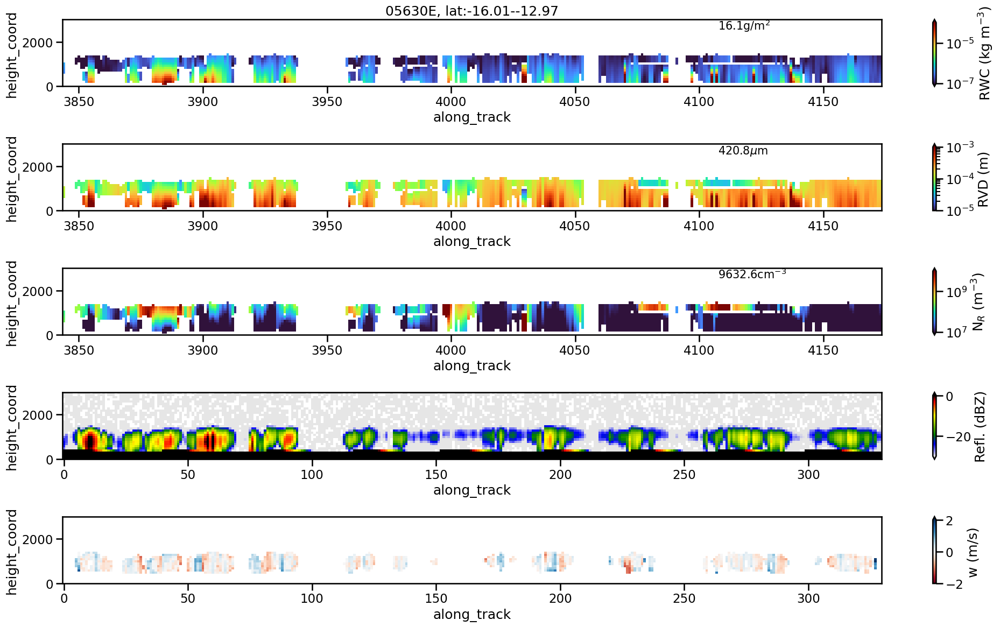

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E.h5
Orbit: 05708E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/05/30/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_05708E/ECA_EXBA_MSI_COP_2A_20250530T194014Z_20250917T144257Z_057

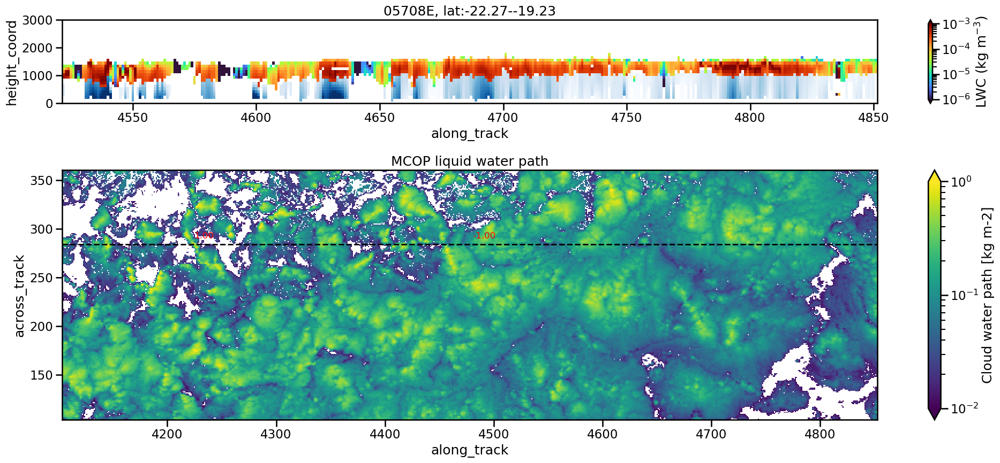

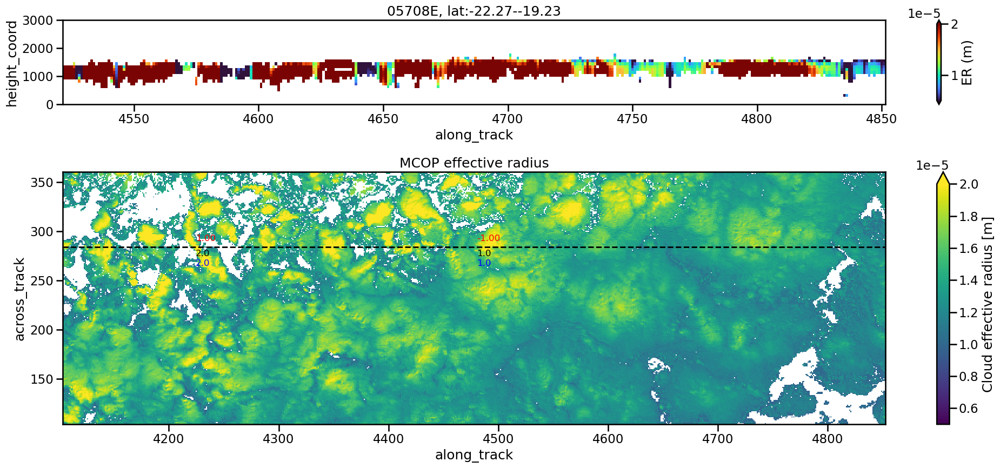

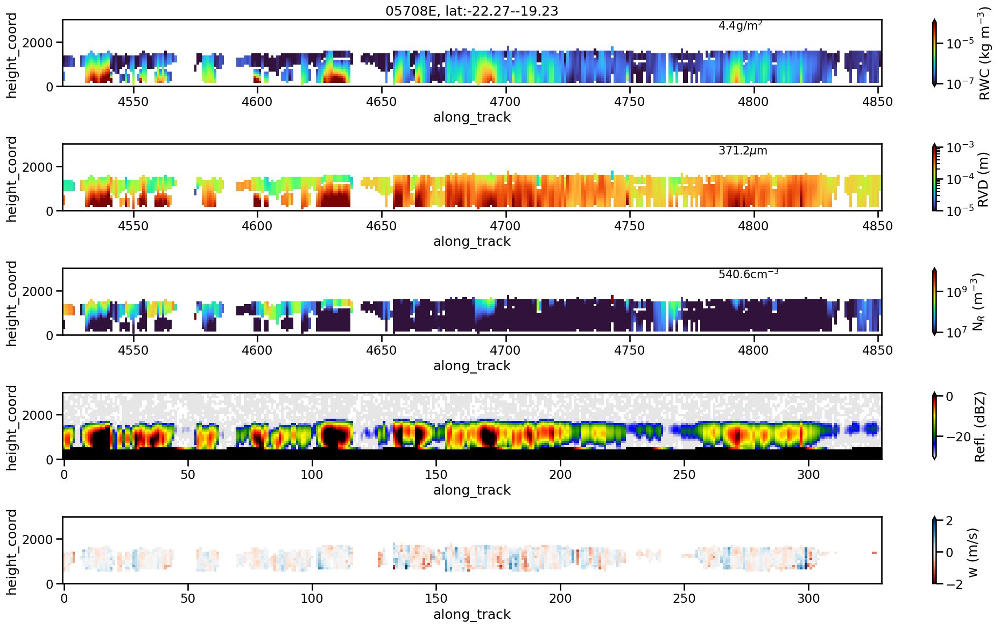

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
Orbit: 06019E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_060

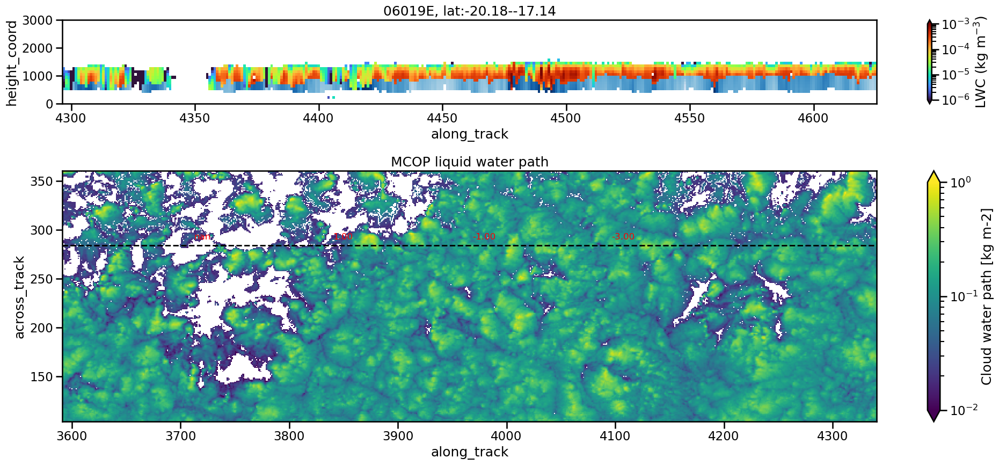

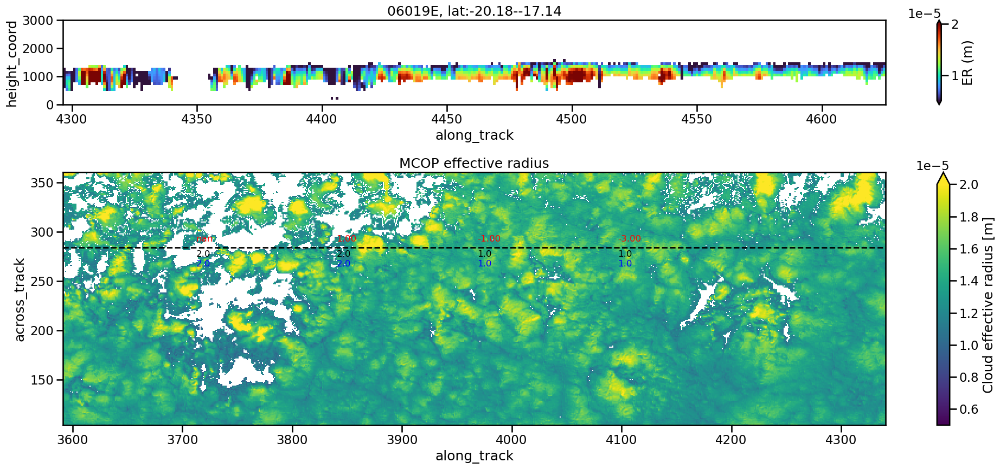

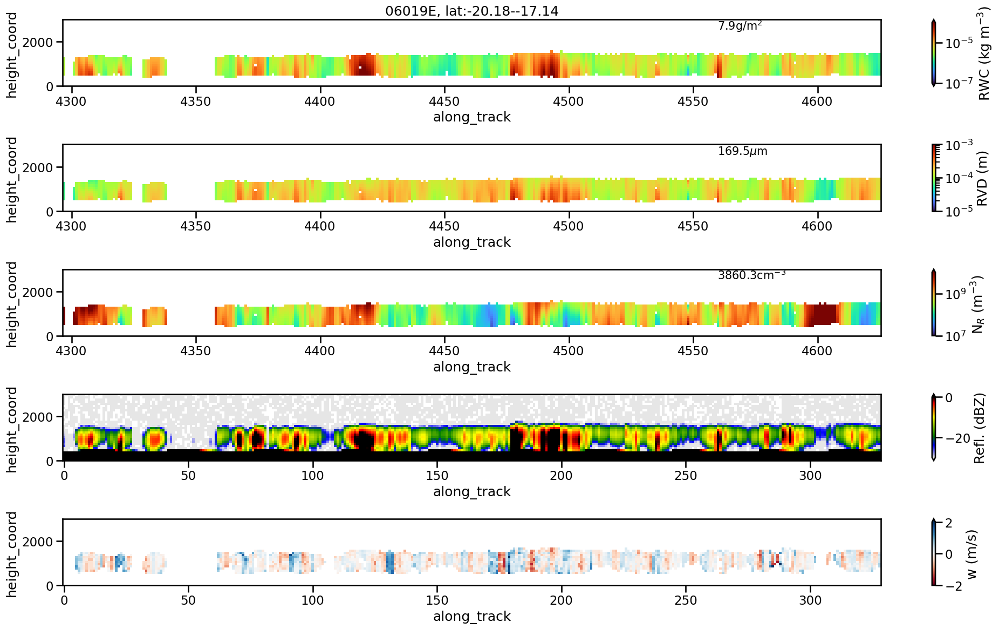

In [35]:
for i,orbit in enumerate(np.unique(ds_at_transition.orbit.values)[:5]):
    ds_at_transition_orbit = ds_at_transition.where(ds_at_transition.orbit == orbit, drop=True)
    lat_min = ds_at_transition_orbit.lat_min.min().values
    lat_max = ds_at_transition_orbit.lat_max.max().values
    plot_ACMCAP_MCOP_for_orbit(orbit, lat_min - 1, lat_max + 1)
    if i >= 5:
        break

In [42]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.orbit=='05848E'), drop=True)[['orbit','transition_time_diff','rwp','lwp','rwp_perc75','lat_mid']]

<xarray.Dataset> Size: 224B
Dimensions:               (time_startpoint: 4)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 32B 2025-06-08T19:...
    orbit                 (time_startpoint) object 32B '05848E' ... '05848E'
Data variables:
    transition_time_diff  (time_startpoint) float64 32B -1.0 -1.0 -1.0 -1.0
    rwp                   (time_startpoint) float64 32B 0.001482 ... 0.000259
    lwp                   (time_startpoint) float64 32B 0.03345 ... 0.01852
    rwp_perc75            (time_startpoint) float64 32B 0.0 0.0 0.0 0.0
    lat_mid               (time_startpoint) float64 32B -6.193 -7.237 ... -9.325

In [119]:
bt_co_concat.where((bt_co_concat.transition_flag == True) & (bt_co_concat.transition_time_diff < 30) & (bt_co_concat.lat_mid < -20), drop=True)[['orbit','transition_time_diff','rwp','lwp','rwp_perc75','lat_mid']]

<xarray.Dataset> Size: 4kB
Dimensions:               (time_startpoint: 78)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 624B 2024-08-07T19...
    orbit                 (time_startpoint) object 624B '01102E' ... '07793E'
Data variables:
    transition_time_diff  (time_startpoint) float64 624B -3.0 -3.0 ... 3.0 12.0
    rwp                   (time_startpoint) float64 624B 0.002659 ... 0.009056
    lwp                   (time_startpoint) float64 624B 0.07601 ... 0.009783
    rwp_perc75            (time_startpoint) float64 624B 0.003181 ... 0.005266
    lat_mid               (time_startpoint) float64 624B -20.26 ... -20.79

### example for publication

In [53]:
bt_example = bt_co_concat.where((bt_co_concat.orbit == '06019E') & (bt_co_concat.lat_min >= -19.18-1) & (bt_co_concat.lat_max <= -18.14+1.5), drop=True)
bt_example = bt_example.sortby('time_startpoint')
bt_example[['lat_min', 'lat_max', 'lat_mid', 'transition_time_diff', 'cats', 'along_track_mid']]

<xarray.Dataset> Size: 320B
Dimensions:               (time_startpoint: 4)
Coordinates:
  * time_startpoint       (time_startpoint) datetime64[ns] 32B 2025-06-19T19:...
    orbit                 (time_startpoint) <U6 96B '06019E' ... '06019E'
Data variables:
    lat_min               (time_startpoint) float64 32B -18.14 -18.66 ... -19.7
    lat_max               (time_startpoint) float64 32B -17.1 -17.62 ... -18.66
    lat_mid               (time_startpoint) float64 32B -17.67 -18.19 ... -19.23
    transition_time_diff  (time_startpoint) float64 32B nan 1.0 -1.0 -3.0
    cats                  (time_startpoint) float64 32B 2.0 2.0 1.0 1.0
    along_track_mid       (time_startpoint) float64 32B 3.712e+03 ... 4.096e+03

In [54]:
orbit = '06019E'
lat_min = bt_example.lat_min.min().values
lat_max = bt_example.lat_max.max().values
lon_min = bt_example.lon_mid.min().values
lon_max = bt_example.lon_mid.max().values
lat_min, lat_max

(array(-19.70404768), array(-17.10013199))

In [ ]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import colormaps
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
import access_ec_on_maap as maap
#from importlib import reload
#reload(maap)

dfscene = bt_co_concat.where((bt_co_concat.orbit == orbit) & (bt_co_concat.lat_mid >= lat_min) & (bt_co_concat.lat_mid <= lat_max), drop=True)
time_startpoint = dfscene.time_startpoint.values[0]
year = pd.to_datetime(time_startpoint).year
month = pd.to_datetime(time_startpoint).month
day = pd.to_datetime(time_startpoint).day
region = 'SEP'
transition_params=dfscene[['transition_time_diff','along_track_mid','cats','goes_cats','scene_id']].sel(timestep=0).groupby('scene_id').mean()

# load ACMCAP
try:
    filename = glob.glob(f'/home/jmayer/Object_Data/ACM_CAP_2B/{year}/{month:02d}/{day:02d}/*_{orbit}.h5')[0]
    ACMCAP = ecio.load_ACMCAP(filename)
except IndexError:
    ACMCAP_list = maap.get_acmcap_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    ACMCAP = ACMCAP_list[0][0]

encoding = ACMCAP.encoding
ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
ACMCAP.encoding = encoding.copy()
ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})

# load MCOP
MCOP_list = maap.get_mcop_via_maap(
        region=region, 
        frame=orbit[-1],
        orbitNumber=orbit[:-1],
        mcop_variables=['time', 'latitude', 'longitude', 'cloud_optical_thickness', 'cloud_water_path','cloud_effective_radius'], 
        max_items=1)
    
MCOP, _ = MCOP_list[0]

MCOP = MCOP.assign_coords(
    {
    'along_track': (
        ["along_track"],
        MCOP['along_track'].data,
        MCOP['along_track'].attrs
        ),
    'across_track': (
        ['across_track'],
        MCOP['across_track'].data,
        MCOP['across_track'].attrs
        )
    })
along_track_min = np.abs(MCOP.sel(across_track=284).latitude - lat_min).argmin()
along_track_max = np.abs(MCOP.sel(across_track=284).latitude - lat_max).argmin()
MCOP2 = MCOP.sel(along_track=slice(MCOP.along_track[along_track_max], MCOP.along_track[along_track_min]))
MCOP2 = MCOP2.sel(across_track=slice(360 - 256, 360))

# load C-FMR
CFMR_list = maap.get_cfmr_via_maap(
                    frame=orbit[-1],
                    orbitNumber=orbit[:-1],
                    max_items=1,
                    )
CFMR = CFMR_list[0][0]
CFMR = CFMR.assign_coords(along_track=("along_track", CFMR.along_track.data))
CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)

Selecting frame from 9 to 4877
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E.h5
Orbit: 06019E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/MSI_COP_2A/BA/2025/06/19/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_06019E/ECA_EXBA_MSI_COP_2A_20250619T192126Z_20250929T144124Z_060

4405 4292
4461 4348
4518 4405
4574 4461


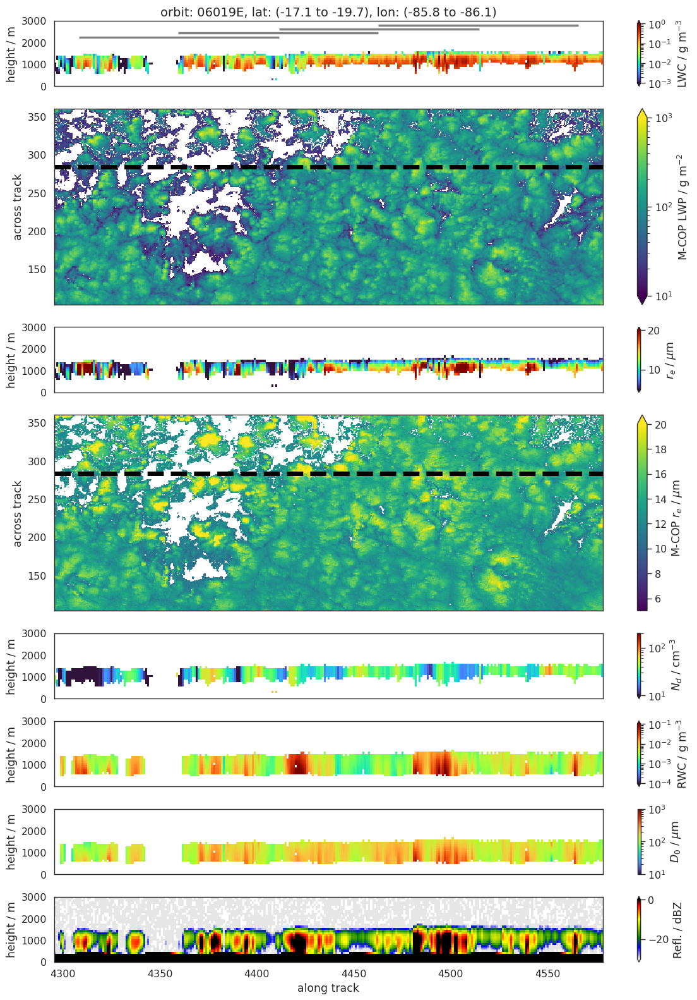

In [56]:
# plot
sns.set_context('paper', font_scale=1.3)
#sns.set_context('talk', font_scale=1.)
sns.set_style('white')

import matplotlib.gridspec as gridspec

fig, axs = plt.subplots(figsize=(12, 16), nrows=8, ncols=1, gridspec_kw={'height_ratios': [1, 3, 1, 3, 1, 1, 1, 1]})


annotation_fontsize = 12
annotation_xy = (0.05, 0.8)

#ACMCAP.rain_water_content.T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-7, vmax=1e-4, norm=LogNorm(), cmap='Blues', add_colorbar=False)
(ACMCAP.liquid_water_content*1e3).T.plot(ax=axs[0], ylim=(0,3000), vmin=1e-3, vmax=1e0, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'LWC / g m$^{-3}$'})
#dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
mean_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
std_LWP = (ACMCAP.liquid_water_content.where(ACMCAP.liquid_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
#axs[0].annotate(fr'mean: {mean_LWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[0].annotate(fr'CV: {std_LWP/mean_LWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
axs[0].set_title(f'orbit: {orbit}, lat: ({lat_max.round(1)} to {lat_min.round(1)}), lon: ({lon_max.round(1)} to {lon_min.round(1)})', fontsize=14)
ax = axs[1]
(MCOP2.cloud_water_path * 1e3).T.plot(ax=ax, cmap='viridis', vmin=1e1, vmax=1e3, norm=LogNorm(), add_colorbar=True, cbar_kwargs={'label': 'M-COP LWP / g m$^{-2}$'})
ax.axhline(284, color='k', linestyle='--', lw=5)
mean_LWP = (MCOP2.cloud_water_path.where((MCOP2.cloud_water_path > 0) & (~np.isinf(MCOP2.cloud_water_path))).mean().values * 1e3)
#ax.annotate(fr'{mean_LWP:.1f}g/m$^{2}$', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
#ax.set_title('M-COP liquid water path')

(ACMCAP.liquid_effective_radius * 1e6).T.plot(ax=axs[2], ylim=(0,3000), vmin=5, vmax=20, cmap='turbo', cbar_kwargs={'label': '$r_e$ / $\mu$m'})
#dffil[dffil.scene_id == dfcat_sel.scene_id.values[0]].lcl.plot(ax=axs[0])
mean_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
std_ER = (ACMCAP.liquid_effective_radius.where(ACMCAP.liquid_water_content > 0).mean(dim='height_coord')).std().values * 1e6
#axs[2].annotate(f'mean: {mean_ER:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[2].annotate(f'CV: {std_ER/mean_ER:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
ax = axs[3]
(MCOP2.cloud_effective_radius * 1e6).T.plot(ax=ax, cmap='viridis', vmin=5, vmax=20, add_colorbar=True, cbar_kwargs={'label': 'M-COP $r_e$ / $\mu$m'})
ax.axhline(284, color='k', linestyle='--', lw=5)
mean_ER = MCOP2.cloud_effective_radius.where(MCOP2.cloud_water_path > 0).mean().values * 1e6
#ax.annotate(f'{mean_ER:.1f}$\mu$m', xy=(0.8,0.9), xycoords='axes fraction', fontsize=15)
#ax.set_title('M-COP effective radius')

(ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0) * 1e-6).T.plot(ax=axs[4], ylim=(0,3000), vmin=1e1, vmax=2e2, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$N_d$ / cm$^{-3}$'})
mean_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).mean().values * 1e-6
std_Nd = (ACMCAP.liquid_number_concentration.where(ACMCAP.liquid_number_concentration > 0).mean(dim='height_coord')).std().values * 1e-6
#axs[4].annotate(f'mean: {mean_Nd:.1f} cm$^{{-3}}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[4].annotate(f'CV: {std_Nd/mean_Nd:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
(ACMCAP.rain_water_content*1e3).T.plot(ax=axs[5], ylim=(0,3000), vmin=1e-4, vmax=1e-1, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': 'RWC / g m$^{-3}$'})
mean_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).mean().values * 1e3
std_RWP = (ACMCAP.rain_water_content.where(ACMCAP.rain_water_content > 0).sum(dim='height_coord')*100).std().values * 1e3
#axs[5].annotate(fr'mean: {mean_RWP:.1f} g/m$^{2}$', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[5].annotate(fr'CV: {std_RWP/mean_RWP:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
(ACMCAP.rain_median_volume_diameter*1e6).T.plot(ax=axs[6], ylim=(0,3000), vmin=1e1, vmax=1e3, norm=LogNorm(), cmap='turbo', cbar_kwargs={'label': '$D_0$ / $\mu$m'})
mean_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).mean().values * 1e6
std_RVD = (ACMCAP.rain_median_volume_diameter.where(ACMCAP.rain_water_content > 0).mean(dim='height_coord')).std().values * 1e6
#axs[6].annotate(fr'mean: {mean_RVD:.1f} $\mu$m', xy=annotation_xy, xycoords='axes fraction', fontsize=annotation_fontsize)
#axs[6].annotate(fr'CV: {std_RVD/mean_RVD:.1f}', xy=(annotation_xy[0], annotation_xy[1]-0.17), xycoords='axes fraction', fontsize=annotation_fontsize)
CFMR.reflectivity_no_attenuation_correction.T.plot(ax=axs[7], cmap=colormaps.chiljet2, vmin=-30, vmax=0, ylim=(0,3000), cbar_kwargs={'label': 'Refl. / dBZ'})

axs[-1].set_ylabel('height / m')
axs[-1].set_xlabel('along track')
for i in [0, 2, 4, 5, 6]:
    axs[i].set_xticks([])
    #axs[i].set_yticks([])
    axs[i].set_xlabel('')
    #axs[i].set_ylabel('')
    axs[i].set_ylabel('height / m')
for i in [1,3]:
    axs[i].set_xticks([])
    #axs[i].set_yticks([])
    axs[i].set_xlabel('')
    #axs[i].set_ylabel('')
    axs[i].set_ylabel('across track')

# additinal axis on top of axs[0] to plot scene extent
ax = axs[0].inset_axes([0, 0.73, 1, 0.22], transform=axs[0].transAxes)
for i in range(len(bt_example.time_startpoint)):
    #colors = [c for c in sns.color_palette('tab10', n_colors=10)]
    idx_min = np.abs(ACMCAP.latitude - bt_example.lat_min[i]).argmin()
    idx_max = np.abs(ACMCAP.latitude - bt_example.lat_max[i]).argmin()
    along_track_min, along_track_max = ACMCAP.along_track[idx_min].values, ACMCAP.along_track[idx_max].values
    print(along_track_min, along_track_max)
    ax.hlines([0+i], xmin=along_track_min, xmax=along_track_max, color='grey', linestyle='-', lw=2.5)
ax.set_ylim(-0.3,3.3)
ax.axis('off')

fig.tight_layout()
plt.savefig(f'./figures/example_transitioning_clouds.png', dpi=300)

### time evolution of examples

In [7]:
dataset_filename = '/home/jmayer/ACI_research/Code/resources_mesoscale_structure/ACMCAP_judge_StCu_1kmres.h5'
acmcap_1km = pd.read_hdf(dataset_filename, key='StCu')

-27.0


NameError: name 'cfmr_scene' is not defined

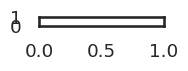

In [ ]:
# create a big figure with many small subplots to compare the different trajectory sets
# the subplots are at x-positions determined by the transition_time_diff values, and y-positions determined s.t. plots dont overlap
hue_variable = 'rwc_cbh'  # can be 'rain_rate_cbh', 'lwp'

fig = plt.figure(figsize=(50, 6))
# Track occupied positions to avoid overlaps
occupied_positions = []  # List of (left, right, bottom, top) rectangles
max_number_of_plots_per_time = 6
subplot_width = 0.025
subplot_height = 1 / max_number_of_plots_per_time * 0.9  # Use 90% of vertical space for subplots

time_min, time_max = -30, 30

sns.set_context('talk', font_scale=0.8)

bt_tmp = bt_co_concat.where(bt_co_concat.transition_flag == 1, drop=True)


for i, dt_ in enumerate(np.unique(bt_tmp.transition_time_diff.values)):
    print(dt_)
    bt_tmp_dt = bt_tmp.where(bt_tmp.transition_time_diff == dt_, drop=True)
    number_of_plots = min(max_number_of_plots_per_time, len(bt_tmp_dt.time_startpoint.values))
    chosen_time_startpoints =np.random.choice(bt_tmp_dt.time_startpoint.values, size=number_of_plots, replace=False)

    for t_ in chosen_time_startpoints:
        bt_tmp_t = bt_tmp.sel(time_startpoint=t_)
        orbit, lat_min, lat_max = bt_tmp_t.orbit.values, bt_tmp_t.lat_min.values, bt_tmp_t.lat_max.values

        acmcap_scene = acmcap_1km[(acmcap_1km.orbit == orbit) & (acmcap_1km.lat_min >= lat_min) & (acmcap_1km.lat_max <= lat_max)]


        def add_profile(profile_arr, cbh_m, cth_m):
            # between dfex.cbh_m and dfex.cth_m (both arrays of size 113), the profile_arr should be filled with 1
            for i in range(len(cth_m)):
                cbh = cbh_m.values[i]
                cth = cth_m.values[i]
                if np.isnan(cbh) or np.isnan(cth):
                    continue
                cbh_idx = int(cbh // 100)
                cth_idx = int(cth // 100)
                # Ensure indices are within bounds
                cbh_idx = max(0, min(cbh_idx, profile_arr.shape[1] - 1))
                cth_idx = max(0, min(cth_idx, profile_arr.shape[1] - 1))
                profile_arr[i, cbh_idx:cth_idx+1] += 1
            return profile_arr
        
        x_length = len(acmcap_scene.latitude)
        profile_arr = xr.DataArray(np.zeros((x_length, 20)), dims=['latitude', 'height'], coords={'latitude': acmcap_scene.latitude.values, 'height': np.arange(20)*100})
        profile_arr = add_profile(profile_arr, acmcap_scene.cbh_m, acmcap_scene.cth_m)
        
        # Calculate normalized x position
        norm_x = (dt_ - time_min) / (time_max - time_min)
        left = 0.05 + norm_x * 0.9  # Use 90% of figure width
        right = left + subplot_width
        
        # Find available vertical position
        bottom = 0.1  # Start from bottom
        found_position = False
        
        while not found_position:
            top = bottom + subplot_height
            
            # Check if this position overlaps with any existing subplot
            overlaps = False
            for occupied in occupied_positions:
                occ_left, occ_right, occ_bottom, occ_top = occupied
                
                # Check for overlap
                if (left < occ_right and right > occ_left and 
                    bottom < occ_top and top > occ_bottom):
                    overlaps = True
                    break
            
            if not overlaps:
                found_position = True
            else:
                bottom += subplot_height + 0.005  # Move up with small gap
        
        # Record this position as occupied
        occupied_positions.append((left, right, bottom, top))
        
        # Create the subplot
        ax = fig.add_axes([left, bottom, subplot_width, subplot_height])
        
        im1 = ax.imshow(profile_arr.T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='Blues')
        if hue_variable == 'rwp':
            im2 = ax.imshow((profile_arr * acmcap_scene.rwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-3, 5e-1))
            #plt.colorbar(im2, ax=ax, label='RR / kg m$^{-2}$ s$^{-1}$')
        elif hue_variable == 'rwc_cbh':
            im2 = ax.imshow((profile_arr * acmcap_scene.rwc_cbh.values[:, np.newaxis] * 1e3).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(5e-4, 1e-1))
        elif hue_variable == 'lwp':
            im2 = ax.imshow((profile_arr * acmcap_scene.lwp.values[:, np.newaxis]).T, origin='lower', aspect='auto', extent=[0,x_length,0,2000], cmap='turbo', norm=LogNorm(1e-4, 5e-1))
            #plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
        #ax.set_xticks(ticks=np.linspace(0, x_length, 3), labels=[f'{lat:.2f}' for lat in np.linspace(acmcap_scene.latitude.values[0], acmcap_scene.latitude.values[-1], 3)])
        #ax.set_title(f'{orbit}, $\Delta$t={time_to_trans}, Scene ID {scene_id}')
        ax.set_axis_off()  # Turn off axis for small plots

# add vertical line at transition time
norm_x = (0 - time_min) / (time_max - time_min)
plt.vlines(x=0.05 + norm_x * 0.9, ymin=0, ymax=1, color='red', linestyle='-', lw=3 )

#max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
ax = fig.add_axes([0.95, 0.5, 0.01, 0.1])  # Position for colorbar
if hue_variable == 'rwp':
    plt.colorbar(im2, ax=ax, label='RWP / kg m$^{-2}$')
elif hue_variable == 'lwp':
    plt.colorbar(im2, ax=ax, label='LWP / kg m$^{-2}$')
ax.set_axis_off()

# plot one big time arrow at the bottom to indicate time axis
ax = fig.add_axes([0.05, 0.05, 0.95, 0.02])  # Position for time axis
ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
ax.text(0, 0.48, f'{time_min} h', ha='center')
ax.text(1, 0.48, f'{time_max} h', ha='center')
ax.text(0.5, 0.48, f'transition', ha='center')
ax.set_axis_off()

In [ ]:
sys.path.append('./../../../ectools/')
from ectools import ecio
from ectools import colormaps
sys.path.append('/home/jmayer/ACI_research/Code/mesoscale_structure/')
import access_ec_on_maap as maap

def get_CFMR_for_scene(orbit, lat_min, lat_max):
    # load C-FMR
    CFMR_list = maap.get_cfmr_via_maap(
                        frame=orbit[-1],
                        orbitNumber=orbit[:-1],
                        max_items=1,
                        )
    CFMR = CFMR_list[0][0]
    CFMR = CFMR.assign_coords(along_track=("along_track", CFMR.along_track.data))
    CFMR = CFMR.assign_coords(height_coord=("CPR_height", CFMR.height.isel(along_track=0).data))
    CFMR = CFMR.where((CFMR.latitude > lat_min) & (CFMR.latitude < lat_max), drop=True)
    CFMR = CFMR.swap_dims({'CPR_height': 'height_coord'})
    CFMR = CFMR.where(CFMR.height_coord > -500, drop=True)
    return CFMR

def get_ACMCAP_for_scene(orbit, lat_min, lat_max):
    # load ACMCAP
    ACMCAP_list = maap.get_acmcap_via_maap(
                            frame=orbit[-1],
                            orbitNumber=orbit[:-1],
                            max_items=1,
                            )
    ACMCAP = ACMCAP_list[0][0]
    encoding = ACMCAP.encoding
    ACMCAP = ACMCAP.where((ACMCAP.latitude > lat_min) & (ACMCAP.latitude < lat_max), drop=True)
    ACMCAP.encoding = encoding.copy()
    ACMCAP = ACMCAP.assign_coords(height_coord=("JSG_height", ACMCAP.height.isel(along_track=0).data))
    ACMCAP = ACMCAP.swap_dims({'JSG_height': 'height_coord'})
    return ACMCAP

def make_examples_along_time_plot(bt_co_concat, variable_to_plot='reflectivity_no_attenuation_correction', vmin=-30, vmax=0, norm=None):
    fig = plt.figure(figsize=(50, 8))
    # Track occupied positions to avoid overlaps
    occupied_positions = []  # List of (left, right, bottom, top) rectangles
    max_number_of_plots_per_time = 6
    subplot_width = 0.025
    subplot_height = 1 / max_number_of_plots_per_time * 0.9  # Use 90% of vertical space for subplots

    time_min, time_max = -30, 30

    sns.set_context('talk', font_scale=0.8)

    bt_tmp = bt_co_concat.where(bt_co_concat.transition_flag == 1, drop=True)


    for i, dt_ in enumerate(np.unique(bt_tmp.transition_time_diff.values)):
        print(dt_)
        bt_tmp_dt = bt_tmp.where(bt_tmp.transition_time_diff == dt_, drop=True)
        number_of_plots = min(max_number_of_plots_per_time, len(bt_tmp_dt.time_startpoint.values))
        rng = np.random.RandomState(42)
        chosen_time_startpoints = rng.choice(bt_tmp_dt.time_startpoint.values, size=number_of_plots, replace=False)

        for t_ in chosen_time_startpoints:
            bt_tmp_t = bt_tmp.sel(time_startpoint=t_)
            orbit, lat_min, lat_max = bt_tmp_t.orbit.values, bt_tmp_t.lat_min.values, bt_tmp_t.lat_max.values

            if variable_to_plot in ['reflectivity_no_attenuation_correction']:
                ec_scene = get_CFMR_for_scene(str(orbit), lat_min, lat_max)
                cmap=colormaps.chiljet2
            else:
                ec_scene = get_ACMCAP_for_scene(str(orbit), lat_min, lat_max)
                cmap='turbo'
            
            # Calculate normalized x position
            norm_x = (dt_ - time_min) / (time_max - time_min)
            left = 0.05 + norm_x * 0.9  # Use 90% of figure width
            right = left + subplot_width
            
            # Find available vertical position
            bottom = 0.1  # Start from bottom
            found_position = False
            
            while not found_position:
                top = bottom + subplot_height
                
                # Check if this position overlaps with any existing subplot
                overlaps = False
                for occupied in occupied_positions:
                    occ_left, occ_right, occ_bottom, occ_top = occupied
                    
                    # Check for overlap
                    if (left < occ_right and right > occ_left and 
                        bottom < occ_top and top > occ_bottom):
                        overlaps = True
                        break
                
                if not overlaps:
                    found_position = True
                else:
                    bottom += subplot_height + 0.005  # Move up with small gap
            
            # Record this position as occupied
            occupied_positions.append((left, right, bottom, top))
            
            # Create the subplot
            ax = fig.add_axes([left, bottom, subplot_width, subplot_height])

            img = ec_scene[variable_to_plot].T.plot(ax=ax, cmap=cmap, vmin=vmin, vmax=vmax, ylim=(0,3000), add_colorbar=False, norm=norm)
            
            ax.set_axis_off()  # Turn off axis for small plots

    # add vertical line at transition time
    norm_x = (0 - time_min) / (time_max - time_min)
    plt.vlines(x=0.05 + norm_x * 0.9, ymin=0, ymax=1, color='red', linestyle='-', lw=3 )

    #max_y_position = np.max([occupied_positions[i][1] for i in range(len(occupied_positions))])
    ax = fig.add_axes([0.95, 0.5, 0.02, 0.2])  # Position for colorbar
    plt.colorbar(img, ax=ax, label=f'{variable_to_plot}')
    ax.set_axis_off()

    # plot one big time arrow at the bottom to indicate time axis
    ax = fig.add_axes([0.05, 0.05, 0.95, 0.02])  # Position for time axis
    ax.arrow(0, 0.5, 1, 0, head_width=0.03, head_length=0.02, length_includes_head=True, fc='black', ec='black')
    ax.text(0, 0.48, f'{time_min} h', ha='center')
    ax.text(1, 0.48, f'{time_max} h', ha='center')
    ax.text(0.5, 0.48, f'transition', ha='center')
    ax.set_axis_off()
    plt.savefig(f'./figures/examples_vs_time_{variable_to_plot}.png', dpi=300)

-27.0
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/CPR_FMR_2A/BA/2025/10/01/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/CPR_FMR_2A/BA/2025/10/01/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E.h5
Orbit: 07637E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/CPR_FMR_2A/BA/2025/10/01/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_20251001T185832Z_20251002T151322Z_07637E/ECA_EXBA_CPR_FMR_2A_2

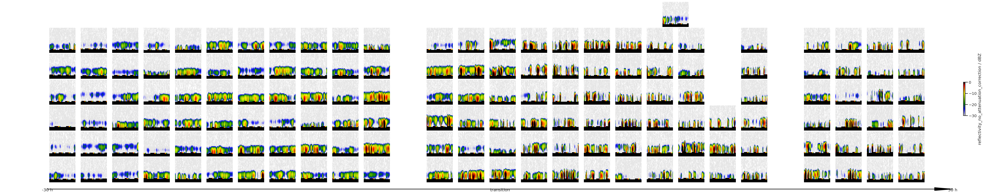

In [28]:
make_examples_along_time_plot(bt_co_concat, variable_to_plot='reflectivity_no_attenuation_correction', vmin=-30, vmax=0)

-27.0
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E.h5
Orbit: 07637E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_2

Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/01/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/01/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E.h5
Orbit: 01009E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2024/08/01/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_20240801T193740Z_20250905T125026Z_01009E/ECA_EXBA_ACM_CAP_2B_2024080

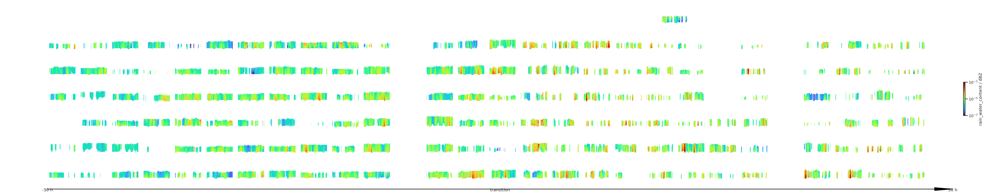

In [29]:
make_examples_along_time_plot(bt_co_concat, variable_to_plot='rain_water_content', vmin=1e-7, vmax=1e-3, norm=LogNorm())

-27.0
Accessing 1 items (limited by max_items).
1 items found that matched the query.
Found .h5 file in enclosure_h5: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E.h5
HDF5 URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E.h5
Orbit: 07637E
Fetching ESA MAAP token...
p1eL7uonXs6MDxtGbgKdPVRAmnGxHpVE
Dataset URL: https://catalog.maap.eo.esa.int/data/earthcare-pdgs-01/EarthCARE/ACM_CAP_2B/BA/2025/10/01/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_20251001T185832Z_20251002T152119Z_07637E/ECA_EXBA_ACM_CAP_2B_2

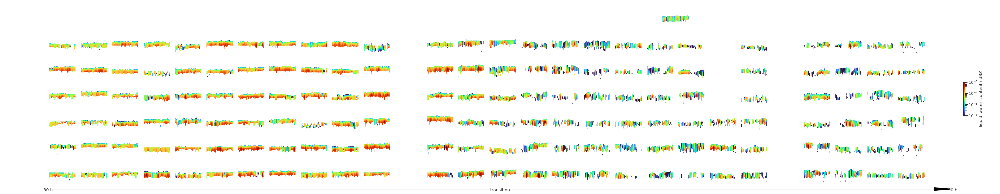

In [30]:
make_examples_along_time_plot(bt_co_concat, variable_to_plot='liquid_water_content', vmin=1e-6, vmax=1e-3, norm=LogNorm())